<a id="indice"></a>

# EDA de venta de propiedades usadas en Moscú

- [1. Preparación y carga de datos](#preparacion)
- [2. Integración de datos y exportación](#integracion)
  - [Limpieza e imputación de datos](#limpieza)
- [3. Análisis univariado](#univariado)
- [4. Análisis bivariado](#bivariado)
  - [Síntesis del análisis bivariado](#resumen-bivariado)
- [5. Correlación y multicolinealidad](#correlacion)
- [6. Análisis temporal de precios, estacionalidad y autocorrelación](#analisis-temporal)


<a id="preparacion"></a>

## 1. Preparación y carga de datos

In [1]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import linregress
from statsmodels.tsa.seasonal import STL
from statsmodels.tsa.stattools import acf
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.stats.multitest import multipletests
from IPython.display import display

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 80)
pd.set_option("display.width", 140)
pd.set_option("display.float_format", "{:,.2f}".format)
sns.set_theme(style="whitegrid", context="notebook", palette="Set2")

# Permitir la ejecucion desde la raiz o desde la carpeta del notebook.
PROJECT_ROOT = next(
    (p for p in (Path.cwd(), *Path.cwd().parents)
     if (p / "Data").is_dir() and (p / "requirements.txt").is_file()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError("No se encontro la raiz del proyecto con Data/ y requirements.txt.")
DATA_DIR = PROJECT_ROOT / "Data"
OUTPUT_PATH = PROJECT_ROOT / "Ventas" / "Propiedades_Usadas" / "PropUsadas_Integrado.csv"

CONFIG = {'labels': {'id': 'ID',
            'date_posted': 'Fecha de publicacion',
            'district': 'Distrito',
            'okrug': 'Okrug',
            'lat': 'Latitud',
            'lon': 'Longitud',
            'total_area': 'Superficie total',
            'living_area': 'Superficie habitable',
            'kitchen_area': 'Superficie de cocina',
            'rooms': 'Habitaciones',
            'floor': 'Piso',
            'total_floors': 'Pisos totales',
            'building_year': 'Anio de construccion',
            'building_type': 'Tipo de edificio',
            'ceiling_height': 'Altura de techo',
            'has_balcony': 'Tiene balcon',
            'renovation': 'Renovacion',
            'metro_station': 'Estacion de metro',
            'metro_line': 'Linea de metro',
            'metro_distance_min': 'Distancia al metro',
            'metro_distance_type': 'Tipo de distancia al metro',
            'to_center_km': 'Distancia al centro',
            'price_rub': 'Precio de venta',
            'price_per_sqm': 'Precio por m2',
            'mortgage_rate_at_listing': 'Tasa hipotecaria',
            'seller_type': 'Tipo de vendedor'},
 'units': {'total_area': 'm²',
           'living_area': 'm²',
           'kitchen_area': 'm²',
           'ceiling_height': 'm',
           'metro_distance_min': 'minutos',
           'to_center_km': 'km',
           'price_rub': 'RUB',
           'price_per_sqm': 'RUB/m²',
           'mortgage_rate_at_listing': '%'}}


In [2]:
df = pd.read_csv(DATA_DIR / "secondary_market.csv")
district_prices = pd.read_csv(DATA_DIR / "district_prices_monthly.csv")
metro_stations = pd.read_csv(DATA_DIR / "metro_stations.csv")

for nombre, datos in [
    ("secondary_market.csv", df),
    ("district_prices_monthly.csv", district_prices),
    ("metro_stations.csv", metro_stations),
]:
    print(f"{nombre}: {datos.shape[0]:,} filas x {datos.shape[1]} columnas")
    display(datos.head(3))

secondary_market.csv: 50,000 filas x 26 columnas
district_prices_monthly.csv: 9,804 filas x 13 columnas
metro_stations.csv: 104 filas x 6 columnas


,id,date_posted,district,okrug,lat,lon,total_area,living_area,kitchen_area,rooms,floor,total_floors,building_year,building_type,ceiling_height,has_balcony,renovation,metro_station,metro_line,metro_distance_min,metro_distance_type,to_center_km,price_rub,price_per_sqm,mortgage_rate_at_listing,seller_type
0,S000001,2024-11-23,Begovoy,SAO,55.80,37.56,71.00,46.50,6.10,2,19,25,1969,khrushchev,2.50,True,cosmetic,Sokol,Zamoskvoretskaya,18,transport,6.17,15739000,221700,23.50,agency
1,S000002,2025-08-13,Sokolniki,VAO,55.80,37.69,79.60,52.80,10.80,3,2,25,2016,modern_panel,2.50,True,no_renovation,Sokolniki,Sokolnicheskaya,7,walk,6.40,19685000,247300,19.50,owner
2,S000003,2022-05-06,Sosenskoye,NAO,55.55,37.43,74.00,42.20,8.90,2,6,9,2016,monolith,3.00,True,cosmetic,Polyanka,Serpukhovsko-Timiryazevskaya,102,transport,25.70,8621000,116400,12.00,owner


,year_month,district,okrug,secondary_price_per_sqm,newbuild_price_per_sqm,rental_price_per_sqm_monthly,secondary_mom_change_pct,newbuild_mom_change_pct,n_listings_secondary,n_listings_newbuild,n_listings_rental,cbr_key_rate_pct,avg_mortgage_rate_pct
0,2020-01,Arbat,CAO,480000,543700,2000,NaN,NaN,104,68,41,6.00,8.50
1,2020-02,Arbat,CAO,469100,531500,1955,-2.28,-2.24,22,63,50,6.00,8.50
2,2020-03,Arbat,CAO,502200,559800,2093,7.07,5.33,104,56,28,6.00,8.50


,station_name,line,lat,lon,year_opened,to_center_km
0,Aleksandrovsky Sad,Filyovskaya,55.75,37.61,1935,0.74
1,Arbatskaya (F),Filyovskaya,55.75,37.60,1935,1.10
2,Bagrationovskaya,Filyovskaya,55.74,37.52,1961,6.53


<a id="integracion"></a>

## 2. Integración de datos

LEFT JOIN por mes de publicación, distrito y okrug; luego por estación y línea de metro.
Se conserva `df` como dataset original y `df_venta_enriquecido` como resultado de la integración. Después de exportarlo, se crea `df_venta_limpio` para los análisis posteriores.

In [3]:
district_join_keys = ["year_month", "district", "okrug"]
district_sales_columns = [
    "secondary_price_per_sqm", "newbuild_price_per_sqm",
    "secondary_mom_change_pct", "newbuild_mom_change_pct",
    "n_listings_secondary", "n_listings_newbuild",
    "cbr_key_rate_pct", "avg_mortgage_rate_pct",
]
metro_join_keys = ["metro_station", "metro_line"]
metro_added_columns = ["metro_lat", "metro_lon", "metro_year_opened", "metro_to_center_km"]

# Las claves auxiliares deben ser unicas para evitar multiplicar anuncios.
for nombre, datos, claves in [
    ("district_prices_monthly.csv", district_prices, district_join_keys),
    ("metro_stations.csv", metro_stations, ["station_name", "line"]),
]:
    duplicadas = datos.duplicated(claves, keep=False)
    print(f"{nombre}: {int(duplicadas.sum()):,} filas con clave duplicada")
    if duplicadas.any():
        display(datos.loc[duplicadas, claves].head(10))
        raise ValueError(f"Clave auxiliar no unica en {nombre}; revisar antes de integrar.")

# Se conserva el mes contemporaneo y las ocho variables de venta del join original.
df_venta_enriquecido = df.copy()
df_venta_enriquecido["date_posted_dt"] = pd.to_datetime(
    df_venta_enriquecido["date_posted"], errors="coerce"
)
df_venta_enriquecido["year_month"] = df_venta_enriquecido["date_posted_dt"].dt.strftime("%Y-%m")
print(f"Fechas sin valor valido para el join: {df_venta_enriquecido['date_posted_dt'].isna().sum():,}")

df_venta_enriquecido = df_venta_enriquecido.merge(
    district_prices[district_join_keys + district_sales_columns],
    how="left", on=district_join_keys,
    validate="many_to_one", indicator="_merge_district_prices",
    suffixes=(False, False),
)
if len(df_venta_enriquecido) != len(df):
    raise ValueError("El join distrital altero la cantidad de anuncios.")

# El prefijo metro_ preserva las coordenadas y distancias de la propiedad.
metro_stations_sales = metro_stations[
    ["station_name", "line", "lat", "lon", "year_opened", "to_center_km"]
].rename(columns={
    "station_name": "metro_station", "line": "metro_line",
    "lat": "metro_lat", "lon": "metro_lon",
    "year_opened": "metro_year_opened", "to_center_km": "metro_to_center_km",
})
df_venta_enriquecido = df_venta_enriquecido.merge(
    metro_stations_sales,
    how="left", on=metro_join_keys,
    validate="many_to_one", indicator="_merge_metro_stations",
    suffixes=(False, False),
)
if len(df_venta_enriquecido) != len(df):
    raise ValueError("El join de metro altero la cantidad de anuncios.")
if not df_venta_enriquecido[df.columns].equals(df):
    raise ValueError("Las columnas originales cambiaron durante la integracion.")

resumen_joins = []
nulos_integracion = []
for nombre, indicador, columnas in [
    ("district_prices_monthly.csv", "_merge_district_prices", district_sales_columns),
    ("metro_stations.csv", "_merge_metro_stations", metro_added_columns),
]:
    sin_match = df_venta_enriquecido[indicador].eq("left_only")
    resumen_joins.append({
        "auxiliar": nombre,
        "filas_antes": len(df), "filas_despues": len(df_venta_enriquecido),
        "sin_correspondencia": int(sin_match.sum()),
        "sin_correspondencia_pct": sin_match.mean() * 100,
    })
    # Separar nulos presentes en filas con match de los causados por falta de match.
    for columna in columnas:
        nulos = df_venta_enriquecido[columna].isna()
        nulos_integracion.append({
            "columna": columna,
            "nulos_con_match": int((nulos & ~sin_match).sum()),
            "nulos_sin_match": int((nulos & sin_match).sum()),
            "nulos_pct": nulos.mean() * 100,
        })

display(pd.DataFrame(resumen_joins).style.format({"sin_correspondencia_pct": "{:.2f}%"}))
display(pd.DataFrame(nulos_integracion).style.format({"nulos_pct": "{:.2f}%"}))
print("Los faltantes se conservan; no se imputan ni se eliminan registros.")
df_venta_enriquecido = df_venta_enriquecido.drop(
    columns=["_merge_district_prices", "_merge_metro_stations"]
)

district_prices_monthly.csv: 0 filas con clave duplicada
metro_stations.csv: 0 filas con clave duplicada
Fechas sin valor valido para el join: 0
Los faltantes se conservan; no se imputan ni se eliminan registros.


,auxiliar,filas_antes,filas_despues,sin_correspondencia,sin_correspondencia_pct
0,district_prices_monthly.csv,50000,50000,0,0.00%
1,metro_stations.csv,50000,50000,0,0.00%


,columna,nulos_con_match,nulos_sin_match,nulos_pct
0,secondary_price_per_sqm,0,0,0.00%
1,newbuild_price_per_sqm,0,0,0.00%
2,secondary_mom_change_pct,678,0,1.36%
3,newbuild_mom_change_pct,678,0,1.36%
4,n_listings_secondary,0,0,0.00%
5,n_listings_newbuild,0,0,0.00%
6,cbr_key_rate_pct,0,0,0.00%
7,avg_mortgage_rate_pct,0,0,0.00%
8,metro_lat,0,0,0.00%
9,metro_lon,0,0,0.00%


<a id="exportacion"></a>

### 2.1. Exportación del dataset integrado

Se exportan todas las variables originales, las temporales y las incorporadas por los joins, sin transformaciones para modelado.

In [4]:
df_venta_enriquecido.to_csv(OUTPUT_PATH, index=False)
df_recargado = pd.read_csv(OUTPUT_PATH, parse_dates=["date_posted_dt"])
if df_recargado.shape != df_venta_enriquecido.shape:
    raise ValueError("Las dimensiones del CSV recargado no coinciden con el DataFrame integrado.")
if df_recargado.columns.tolist() != df_venta_enriquecido.columns.tolist():
    raise ValueError("Las columnas del CSV recargado no coinciden con las exportadas.")
print(f"CSV generado y recargado: {OUTPUT_PATH.relative_to(PROJECT_ROOT)}")
print(f"Dimensiones verificadas: {df_recargado.shape[0]:,} filas x {df_recargado.shape[1]} columnas")
del df_recargado

CSV generado y recargado: Ventas\Propiedades_Usadas\PropUsadas_Integrado.csv
Dimensiones verificadas: 50,000 filas x 40 columnas


<a id="limpieza"></a>

### 2.2. Limpieza e imputación de datos

Se crea `df_venta_limpio` a partir del integrado: primero se eliminan únicamente las superficies inconsistentes con tres valores finitos; después se imputan las dos variaciones mensuales con sus respectivas medias, calculadas sobre los anuncios restantes.
El CSV integrado y `df_venta_enriquecido` conservan los datos anteriores a la limpieza.

Los faltantes de las variaciones corresponden a enero de 2020, al inicio de la serie: su origen es **temporal y no necesariamente aleatorio**. Esta imputación se usa para el EDA; al entrenar y evaluar modelos, las medias deben estimarse **solo con entrenamiento** y aplicarse a validación y test para evitar *data leakage*.

In [5]:
# 1. Eliminar solo superficies inconsistentes cuando las tres medidas son validas.
columnas_superficie = ["living_area", "kitchen_area", "total_area"]
superficies_validas = np.isfinite(df_venta_enriquecido[columnas_superficie]).all(axis=1)
superficies_inconsistentes = superficies_validas & (
    df_venta_enriquecido["living_area"] + df_venta_enriquecido["kitchen_area"]
    > df_venta_enriquecido["total_area"]
)
df_venta_limpio = df_venta_enriquecido.loc[~superficies_inconsistentes].copy()
resumen_limpieza = pd.DataFrame([{
    "observaciones_originales": len(df_venta_enriquecido),
    "registros_eliminados": int(superficies_inconsistentes.sum()),
    "observaciones_finales": len(df_venta_limpio),
}])
display(resumen_limpieza)

# 2. Imputar con la media no nula de cada columna, despues de eliminar las filas.
columnas_imputar = ["secondary_mom_change_pct", "newbuild_mom_change_pct"]
resumen_imputacion = []
for columna in columnas_imputar:
    faltantes_antes = int(df_venta_limpio[columna].isna().sum())
    media = df_venta_limpio[columna].mean(skipna=True)
    if faltantes_antes and pd.isna(media):
        raise ValueError(f"No hay valores observados para calcular la media de {columna}.")
    df_venta_limpio[columna] = df_venta_limpio[columna].fillna(media)
    resumen_imputacion.append({
        "variable": columna,
        "faltantes_antes": faltantes_antes,
        "media_utilizada": media,
        "faltantes_despues": int(df_venta_limpio[columna].isna().sum()),
    })
resumen_imputacion = pd.DataFrame(resumen_imputacion)
display(resumen_imputacion.style.format({"media_utilizada": "{:.6f}"}))
if df_venta_limpio[columnas_imputar].isna().any().any():
    raise ValueError("Quedan valores faltantes en las variables indicadas.")

,observaciones_originales,registros_eliminados,observaciones_finales
0,50000,247,49753


,variable,faltantes_antes,media_utilizada,faltantes_despues
0,secondary_mom_change_pct,672,0.625096,0
1,newbuild_mom_change_pct,672,0.671677,0


<a id="univariado"></a>

## 3. Análisis univariado

Se estudia `df_venta_limpio`, obtenido tras la eliminación por superficies y la imputación documentadas en la sección 2.2. Los análisis no aplican cambios adicionales. Los indicadores auxiliares se describen por anuncio: un mismo contexto de distrito/mes o estación puede repetirse en muchas filas.
`id` se revisa como identificador; `date_posted_dt` representa la fecha de publicación y `year_month` su resumen mensual, sin duplicar el análisis de `date_posted`.

### 3.1. Estadísticas descriptivas

Las frecuencias incluyen los faltantes en el denominador. Se señala escasa variabilidad cuando un único valor concentra al menos el 95 % de los datos observados; no se confunde una escala pequeña con baja variabilidad.

In [6]:
datos_univariados = df_venta_limpio.copy(deep=True)
continuas_uni = [
    "total_area", "living_area", "kitchen_area", "ceiling_height",
    "lat", "lon", "to_center_km", "metro_to_center_km", "metro_lat", "metro_lon",
    "price_per_sqm", "mortgage_rate_at_listing", "secondary_price_per_sqm",
    "newbuild_price_per_sqm", "secondary_mom_change_pct", "newbuild_mom_change_pct",
    "cbr_key_rate_pct", "avg_mortgage_rate_pct",
]
discretas_uni = ["rooms", "floor", "total_floors", "metro_distance_min",
                 "n_listings_secondary", "n_listings_newbuild"]
categoricas_uni = ["district", "okrug", "building_type", "renovation", "metro_station",
                   "metro_line", "metro_distance_type", "seller_type"]
binarias_uni = ["has_balcony"]
anios_uni = ["building_year", "metro_year_opened"]
grupos_uni = {
    "Continuas": continuas_uni, "Discretas": discretas_uni,
    "Categoricas": categoricas_uni, "Binarias": binarias_uni,
    "Temporales": ["date_posted_dt", "year_month", *anios_uni],
}
# La distancia al metro se registra en minutos enteros: se grafica como medida discreta.
clasificacion_uni = pd.DataFrame([
    {"naturaleza": grupo, "variables": ", ".join(columnas)}
    for grupo, columnas in grupos_uni.items()
])
display(clasificacion_uni)

numericas_uni = ["price_rub", *continuas_uni, *discretas_uni, *anios_uni]
estadistica_numerica = datos_univariados[numericas_uni].describe().T.rename(columns={
    "count": "n", "mean": "media", "std": "desv_estandar", "min": "minimo",
    "25%": "Q1", "50%": "mediana", "75%": "Q3", "max": "maximo",
})
display(estadistica_numerica)

calidad_univariada = pd.DataFrame({
    "faltantes": datos_univariados.isna().sum(),
    "faltantes_pct": datos_univariados.isna().mean() * 100,
    "valores_distintos": datos_univariados.nunique(),
    "valor_dominante_pct": [
        datos_univariados[c].value_counts(normalize=True).max() * 100
        for c in datos_univariados
    ],
})
calidad_univariada["constante"] = calidad_univariada["valores_distintos"].eq(1)
calidad_univariada["escasa_variabilidad"] = (
    calidad_univariada["valor_dominante_pct"].ge(95) & ~calidad_univariada["constante"]
)
atencion_calidad = calidad_univariada.loc[
    calidad_univariada["faltantes"].gt(0) | calidad_univariada["constante"]
    | calidad_univariada["escasa_variabilidad"]
]
display(atencion_calidad)
print(f"Constantes: {calidad_univariada['constante'].sum()}; "
      f"con escasa variabilidad: {calidad_univariada['escasa_variabilidad'].sum()}; "
      f"filas duplicadas: {datos_univariados.duplicated().sum():,}; "
      f"ID repetidos: {datos_univariados['id'].duplicated().sum():,}")

# Las tablas completas quedan disponibles; la vista de alta cardinalidad agrupa el resto.
tablas_frecuencia = {}
frecuencias_visuales = {}
resumen_categoricas = []
for variable in categoricas_uni + binarias_uni:
    serie = datos_univariados[variable].astype("object").where(
        datos_univariados[variable].notna(), "Sin dato"
    ).astype(str)
    tabla = serie.value_counts().rename_axis("categoria").reset_index(name="frecuencia_absoluta")
    tabla["frecuencia_relativa_pct"] = tabla["frecuencia_absoluta"] / len(serie) * 100
    tablas_frecuencia[variable] = tabla
    resumen_categoricas.append({
        "variable": variable, "categorias": len(tabla),
        "mas_frecuente": tabla.iloc[0]["categoria"],
        "frecuencia_absoluta": tabla.iloc[0]["frecuencia_absoluta"],
        "frecuencia_relativa_pct": tabla.iloc[0]["frecuencia_relativa_pct"],
    })
    vista = tabla.copy()
    if len(tabla) > 15:
        resto = tabla.iloc[10:]
        vista = pd.concat([tabla.head(10), pd.DataFrame([{
            "categoria": f"Otras ({len(resto)} categorias)",
            "frecuencia_absoluta": resto["frecuencia_absoluta"].sum(),
            "frecuencia_relativa_pct": resto["frecuencia_relativa_pct"].sum(),
        }])], ignore_index=True)
    frecuencias_visuales[variable] = vista.sort_values("frecuencia_absoluta", ascending=False)
display(pd.DataFrame(resumen_categoricas))

Constantes: 0; con escasa variabilidad: 0; filas duplicadas: 0; ID repetidos: 0


,naturaleza,variables
0,Continuas,"total_area, living_area, kitchen_area, ceiling..."
1,Discretas,"rooms, floor, total_floors, metro_distance_min..."
2,Categoricas,"district, okrug, building_type, renovation, me..."
3,Binarias,has_balcony
4,Temporales,"date_posted_dt, year_month, building_year, met..."


,n,media,desv_estandar,minimo,Q1,mediana,Q3,maximo
price_rub,"49,753.00","13,150,568.05","8,569,853.58","1,073,000.00","7,509,000.00","11,111,000.00","16,415,000.00","93,437,000.00"
total_area,"49,753.00",67.20,17.22,21.10,54.60,65.20,77.60,134.30
living_area,"49,753.00",41.97,11.17,12.60,33.80,40.60,48.60,89.20
kitchen_area,"49,753.00",11.23,2.85,6.00,9.20,11.10,13.10,24.80
ceiling_height,"49,753.00",2.79,0.22,2.50,2.70,2.70,3.00,3.50
lat,"49,753.00",55.71,0.14,55.23,55.64,55.74,55.82,56.02
lon,"49,753.00",37.54,0.18,36.70,37.47,37.57,37.65,37.92
to_center_km,"49,753.00",16.33,12.74,0.07,9.03,13.23,18.06,70.55
metro_to_center_km,"49,753.00",7.36,4.85,0.33,2.83,6.83,11.02,20.02
metro_lat,"49,753.00",55.74,0.06,55.60,55.72,55.75,55.78,55.86


,faltantes,faltantes_pct,valores_distintos,valor_dominante_pct,constante,escasa_variabilidad


,variable,categorias,mas_frecuente,frecuencia_absoluta,frecuencia_relativa_pct
0,district,129,Begovoy,433,0.87
1,okrug,11,SVAO,6632,13.33
2,building_type,6,panel,10090,20.28
3,renovation,4,cosmetic,19947,40.09
4,metro_station,104,Rechnoy Vokzal,953,1.92
5,metro_line,12,Kaluzhsko-Rizhskaya,7129,14.33
6,metro_distance_type,2,transport,39577,79.55
7,seller_type,2,agency,32542,65.41
8,has_balcony,2,True,37305,74.98


### 3.2. Análisis de la variable objetivo

Se consideran extremos estadísticos los precios fuera de `[Q1 − 1,5 × IQR, Q3 + 1,5 × IQR]`, con `IQR = Q3 − Q1`. El boxplot y el histograma incluyen todos los precios observados. El logaritmo natural se calcula solo para la comparación gráfica de los valores positivos.

Precios no positivos excluidos solo del grafico logaritmico: 0


,valor
n,"49,753.00"
media_RUB,"13,150,568.05"
mediana_RUB,"11,111,000.00"
desv_estandar_RUB,"8,569,853.58"
IQR_RUB,"8,906,000.00"
coef_variacion_pct,65.17
asimetria,2.00
limite_inferior_IQR_RUB,"-5,850,000.00"
limite_superior_IQR_RUB,"29,774,000.00"
extremos_inferiores,0.00


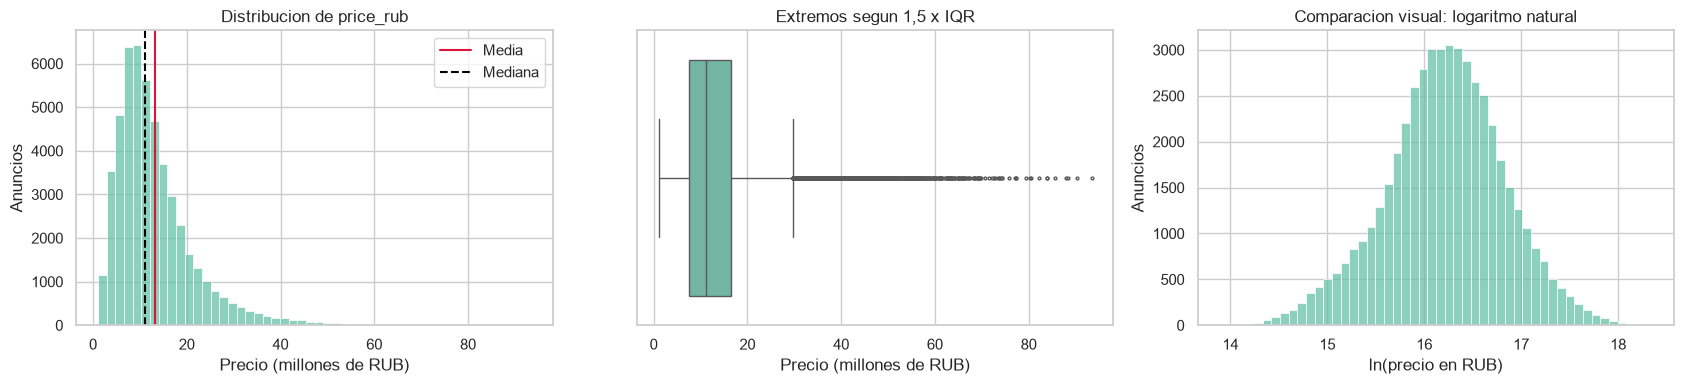

,anuncios,porcentaje_total
price_rub,,
Hasta 10 M RUB,21327,42.87
10 a 20 M RUB,20736,41.68
20 a 30 M RUB,5292,10.64
Mas de 30 M RUB,2398,4.82


In [7]:
precios = datos_univariados["price_rub"].dropna()
q1_precio, mediana_precio, q3_precio = precios.quantile([.25, .50, .75])
iqr_precio = q3_precio - q1_precio
limite_inferior_precio = q1_precio - 1.5 * iqr_precio
limite_superior_precio = q3_precio + 1.5 * iqr_precio
extremos_precio = (precios < limite_inferior_precio) | (precios > limite_superior_precio)
resumen_precio = pd.Series({
    "n": precios.size, "media_RUB": precios.mean(), "mediana_RUB": mediana_precio,
    "desv_estandar_RUB": precios.std(), "IQR_RUB": iqr_precio,
    "coef_variacion_pct": precios.std() / precios.mean() * 100,
    "asimetria": precios.skew(), "limite_inferior_IQR_RUB": limite_inferior_precio,
    "limite_superior_IQR_RUB": limite_superior_precio,
    "extremos_inferiores": (precios < limite_inferior_precio).sum(),
    "extremos_superiores": (precios > limite_superior_precio).sum(),
    "extremos_pct_validos": extremos_precio.mean() * 100,
    "extremos_pct_total": extremos_precio.sum() / len(datos_univariados) * 100,
}, name="valor")
display(resumen_precio.to_frame())

fig, axes = plt.subplots(1, 3, figsize=(17, 4))
sns.histplot(precios / 1_000_000, bins=50, ax=axes[0])
axes[0].axvline(precios.mean() / 1_000_000, color="crimson", label="Media")
axes[0].axvline(mediana_precio / 1_000_000, color="black", linestyle="--", label="Mediana")
axes[0].set(title="Distribucion de price_rub", xlabel="Precio (millones de RUB)", ylabel="Anuncios")
axes[0].legend()
sns.boxplot(x=precios / 1_000_000, ax=axes[1], fliersize=2)
axes[1].set(title="Extremos segun 1,5 x IQR", xlabel="Precio (millones de RUB)")
positivos = precios[precios > 0]
sns.histplot(np.log(positivos), bins=50, ax=axes[2])
axes[2].set(title="Comparacion visual: logaritmo natural", xlabel="ln(precio en RUB)", ylabel="Anuncios")
print(f"Precios no positivos excluidos solo del grafico logaritmico: {(precios <= 0).sum():,}")
fig.tight_layout()
plt.show()

rangos_precio = pd.cut(precios, bins=[0, 10e6, 20e6, 30e6, np.inf],
                      labels=["Hasta 10 M RUB", "10 a 20 M RUB", "20 a 30 M RUB", "Mas de 30 M RUB"])
concentracion_precio = rangos_precio.value_counts(sort=False).to_frame("anuncios")
concentracion_precio["porcentaje_total"] = concentracion_precio["anuncios"] / len(datos_univariados) * 100
display(concentracion_precio)

### 3.3. Análisis de las características predictoras

Las medidas continuas y los conteos se muestran por separado, con todos los datos observados. `price_per_sqm` se conserva para describir el dataset, aunque deriva del precio objetivo y la superficie.
En las categorías de alta cardinalidad, las tablas resumen las diez más frecuentes y el resto agregado. Los gráficos comparan esas diez categorías con su propia escala e indican su cobertura del total; las tablas completas de **todas** las categorías están en `tablas_frecuencia`.

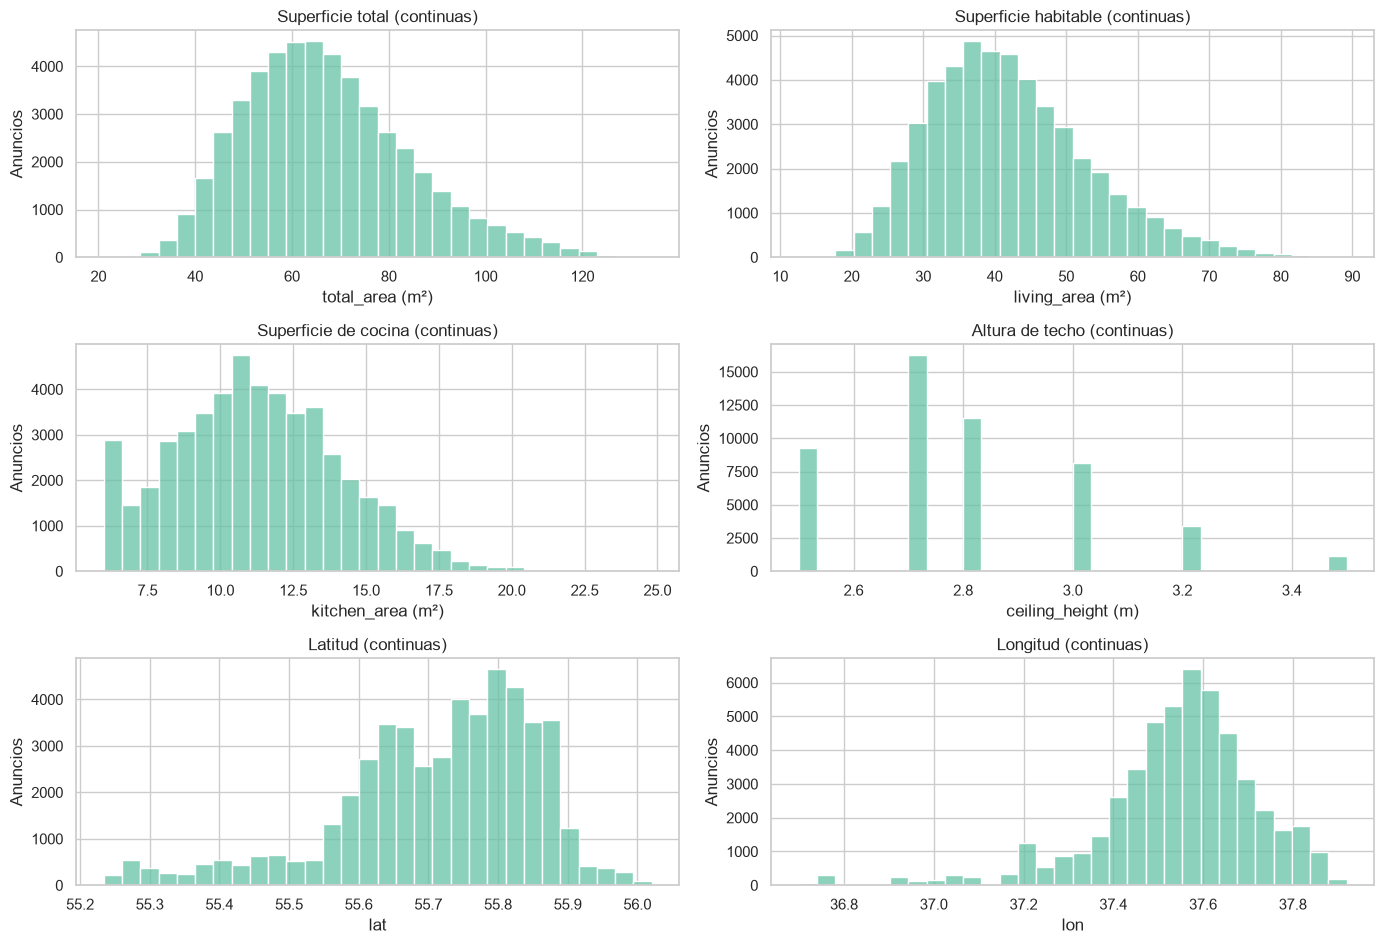

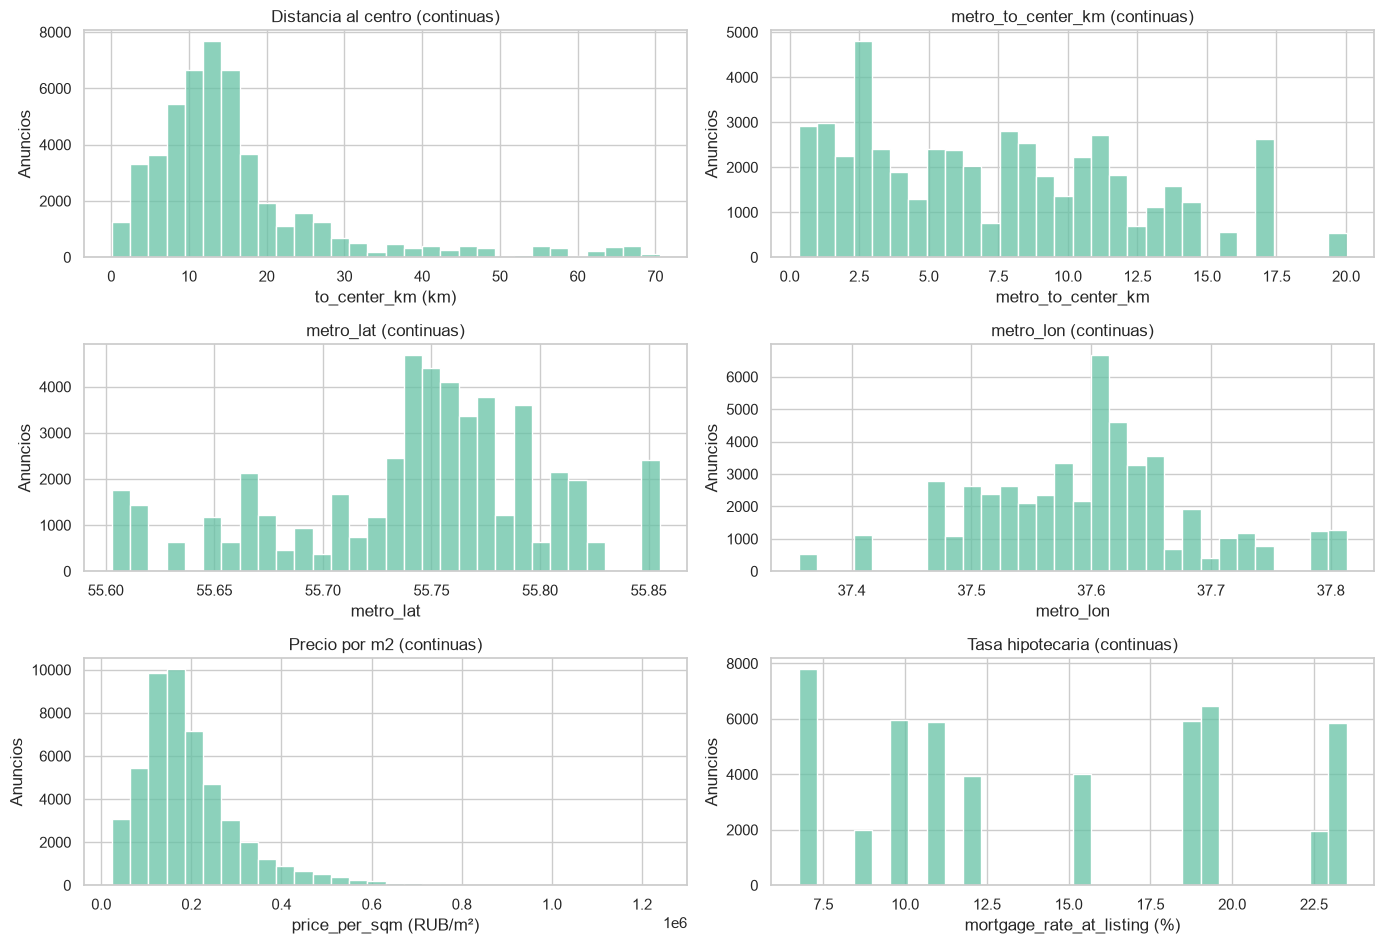

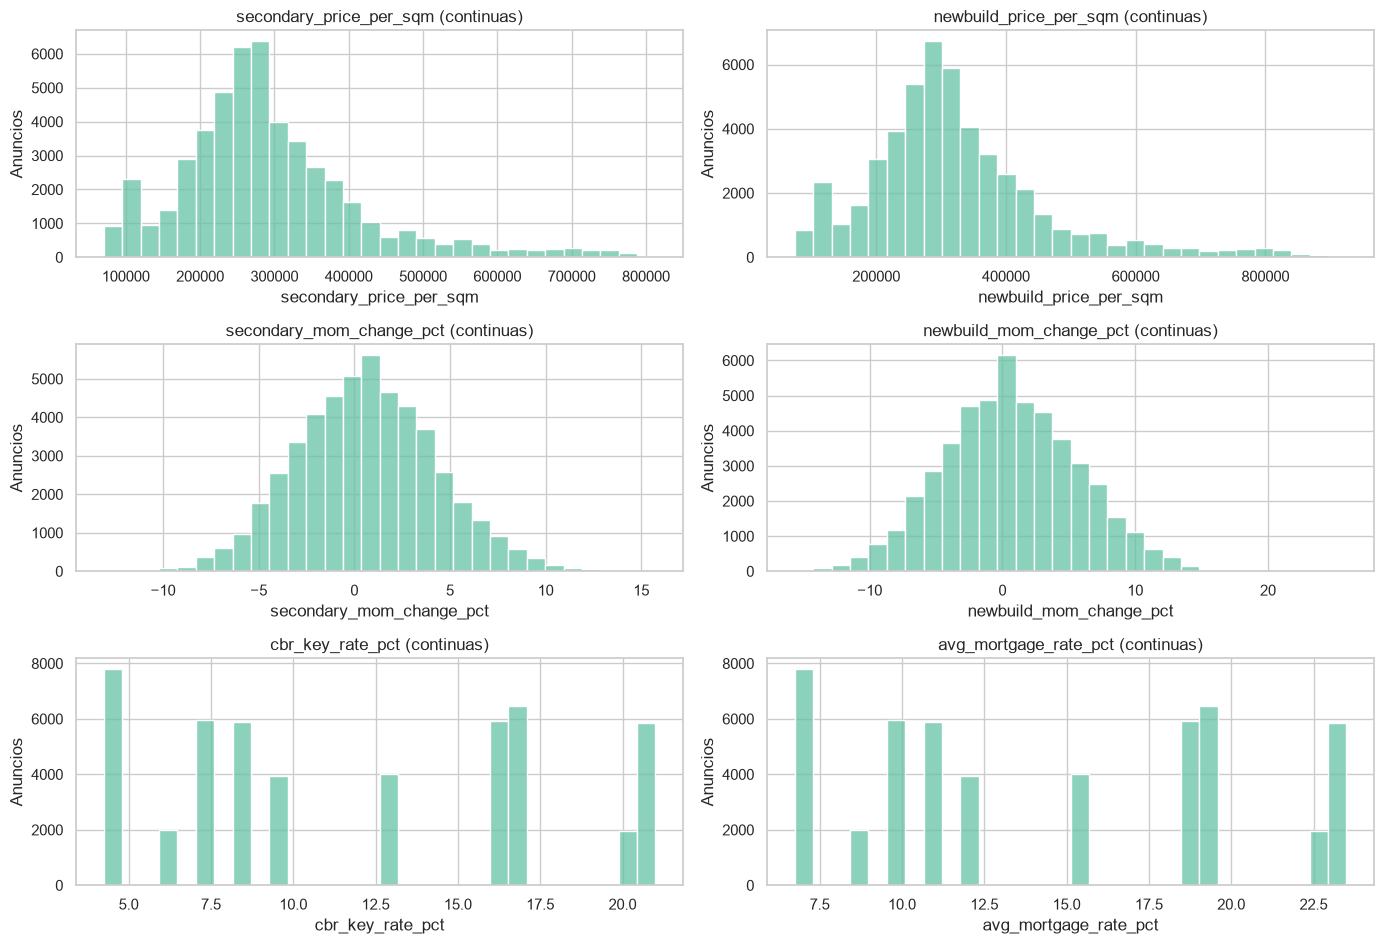

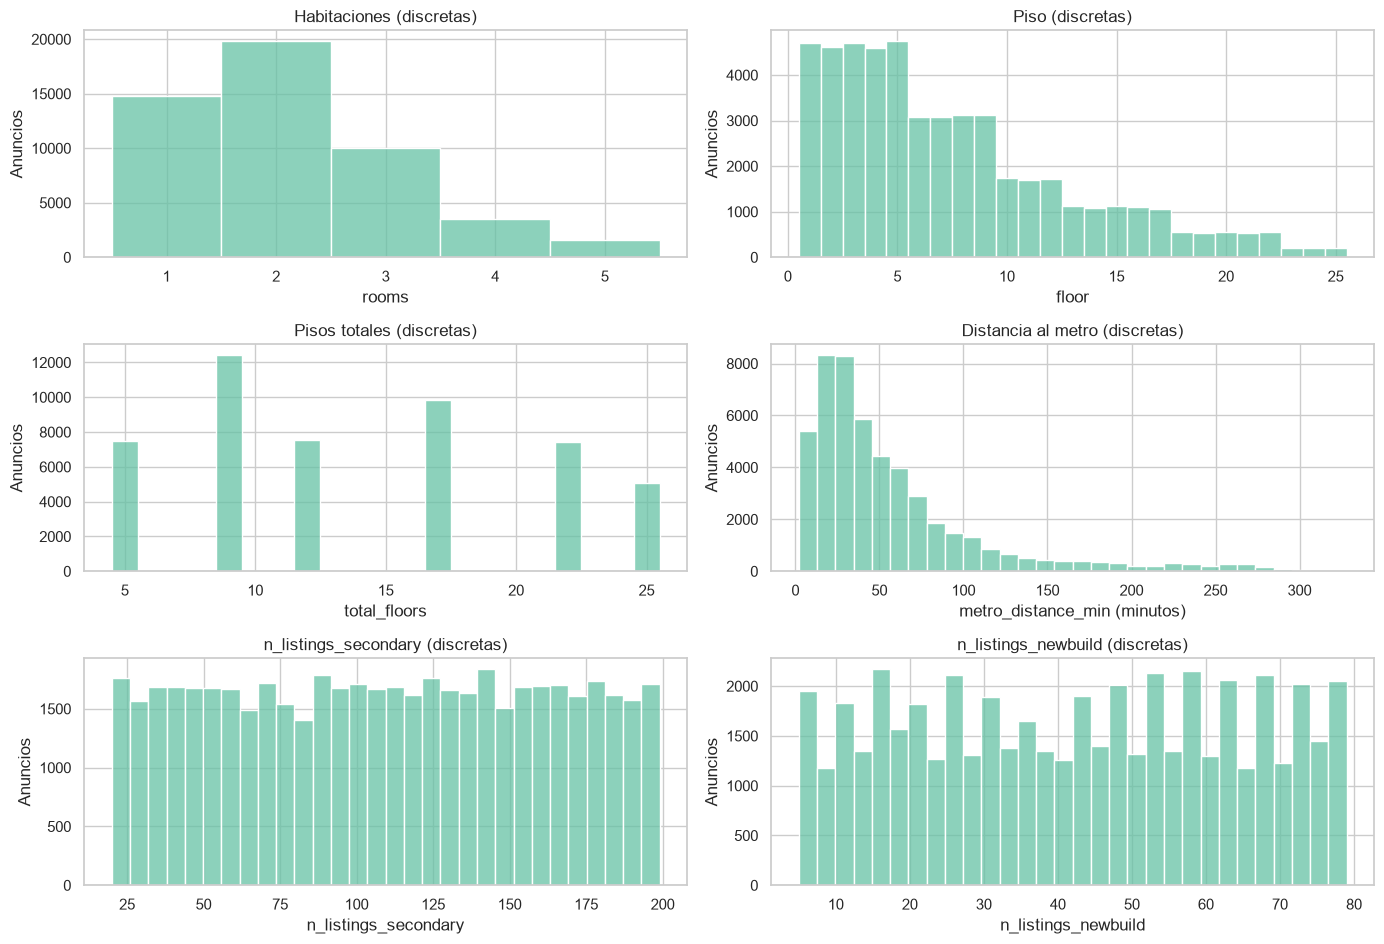

In [8]:
for naturaleza, variables in [("Continuas", continuas_uni), ("Discretas", discretas_uni)]:
    # Lotes pequenos para mantener legibles las escalas y etiquetas.
    for inicio in range(0, len(variables), 6):
        lote = variables[inicio:inicio + 6]
        fig, axes = plt.subplots(int(np.ceil(len(lote) / 2)), 2,
                                 figsize=(14, 3.2 * int(np.ceil(len(lote) / 2))), squeeze=False)
        for ax, variable in zip(axes.flat, lote):
            serie = datos_univariados[variable].dropna()
            discreta = naturaleza == "Discretas" and serie.nunique() <= 30
            sns.histplot(serie, discrete=discreta, bins="auto" if discreta else 30, ax=ax)
            titulo = CONFIG["labels"].get(variable, variable)
            unidad = CONFIG["units"].get(variable, "")
            ax.set(title=f"{titulo} ({naturaleza.lower()})",
                   xlabel=f"{variable} ({unidad})" if unidad else variable, ylabel="Anuncios")
        for ax in list(axes.flat)[len(lote):]:
            ax.set_visible(False)
        fig.tight_layout()
        plt.show()

district
Otras 119 categorias: 91.6% del total; incluidas en la tabla.
okrug
building_type
renovation
metro_station
Otras 94 categorias: 83.5% del total; incluidas en la tabla.
metro_line
metro_distance_type
seller_type
has_balcony


,categoria,frecuencia_absoluta,frecuencia_relativa_pct
0,Otras (119 categorias),45556,91.56
1,Begovoy,433,0.87
2,Yasenevo,429,0.86
3,Mikhaylovo-Yartsevskoye,425,0.85
4,Voronovskoye,421,0.85
5,Timiryazevsky,417,0.84
6,Orekhovo-Borisovo Yuzhnoye,417,0.84
7,Lomonosovsky,415,0.83
8,Bibirevo,414,0.83
9,Akademichesky,413,0.83


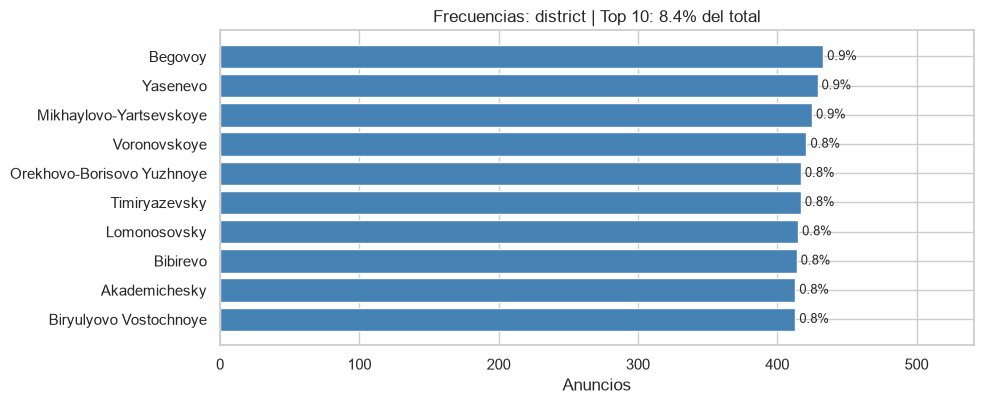

,categoria,frecuencia_absoluta,frecuencia_relativa_pct
0,SVAO,6632,13.33
1,YuAO,6192,12.45
2,VAO,6066,12.19
3,SAO,5835,11.73
4,YuZAO,4734,9.52
5,ZAO,4590,9.23
6,NAO,4146,8.33
7,TAO,3929,7.90
8,CAO,3872,7.78
9,SZAO,3400,6.83


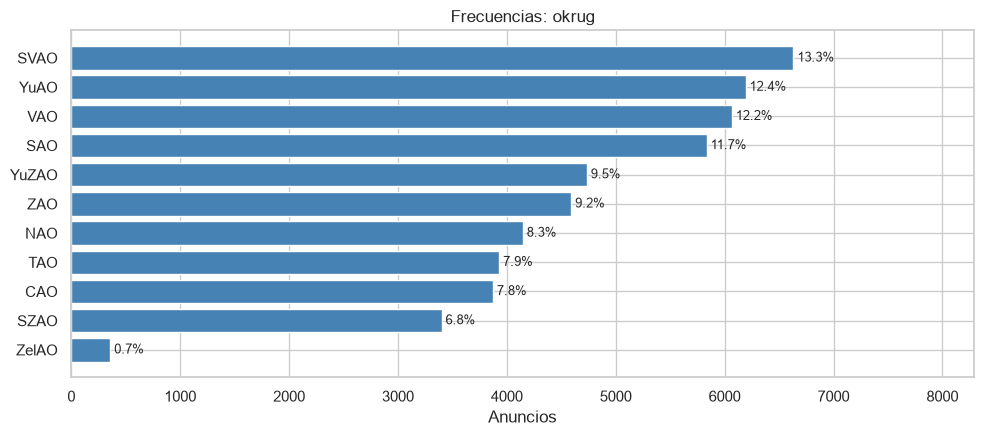

,categoria,frecuencia_absoluta,frecuencia_relativa_pct
0,panel,10090,20.28
1,monolith,9947,19.99
2,modern_panel,9922,19.94
3,brick,8802,17.69
4,khrushchev,7490,15.05
5,stalin,3502,7.04


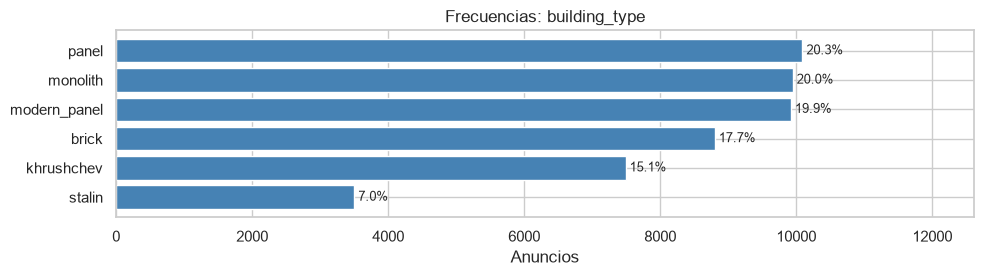

,categoria,frecuencia_absoluta,frecuencia_relativa_pct
0,cosmetic,19947,40.09
1,euro,14898,29.94
2,no_renovation,9991,20.08
3,designer,4917,9.88


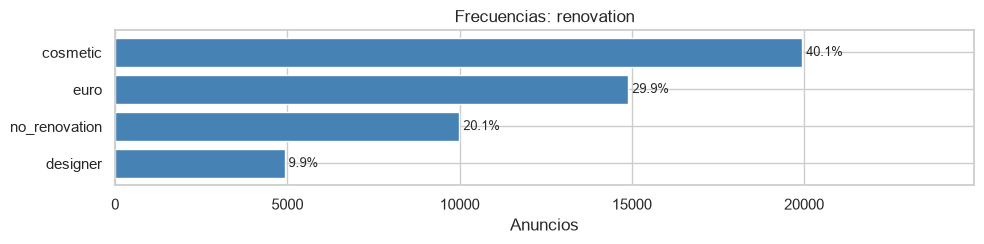

,categoria,frecuencia_absoluta,frecuencia_relativa_pct
0,Otras (94 categorias),41529,83.47
1,Rechnoy Vokzal,953,1.92
2,Sviblovo,923,1.86
3,Yasenevo,912,1.83
4,Tyoply Stan,865,1.74
5,Ulitsa Akademika Yangelya,840,1.69
6,Novye Cheryomushki,782,1.57
7,Shchukinskaya,740,1.49
8,Perovo,739,1.49
9,Timiryazevskaya,738,1.48


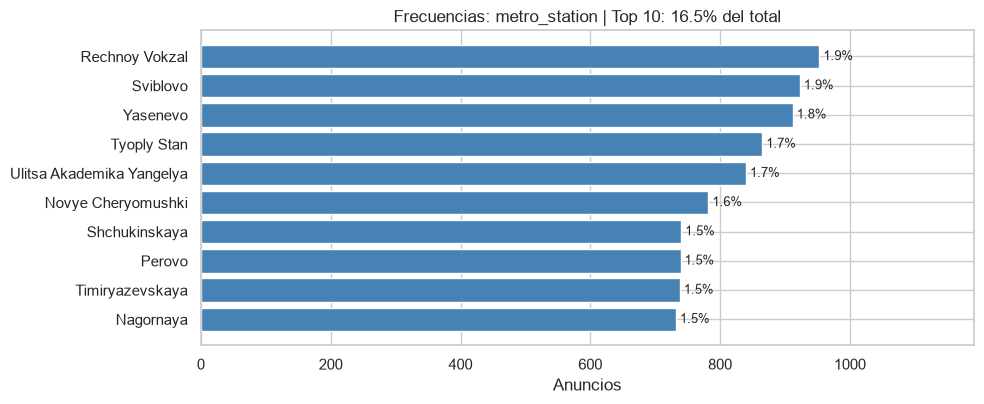

,categoria,frecuencia_absoluta,frecuencia_relativa_pct
0,Kaluzhsko-Rizhskaya,7129,14.33
1,Serpukhovsko-Timiryazevskaya,6712,13.49
2,Sokolnicheskaya,6382,12.83
3,Arbatsko-Pokrovskaya,5739,11.53
4,Zamoskvoretskaya,4987,10.02
5,Koltsevaya,4141,8.32
6,Filyovskaya,4061,8.16
7,Tagansko-Krasnopresnenskaya,3406,6.85
8,Lyublinsko-Dmitrovskaya,2997,6.02
9,Kalininskaya,2364,4.75


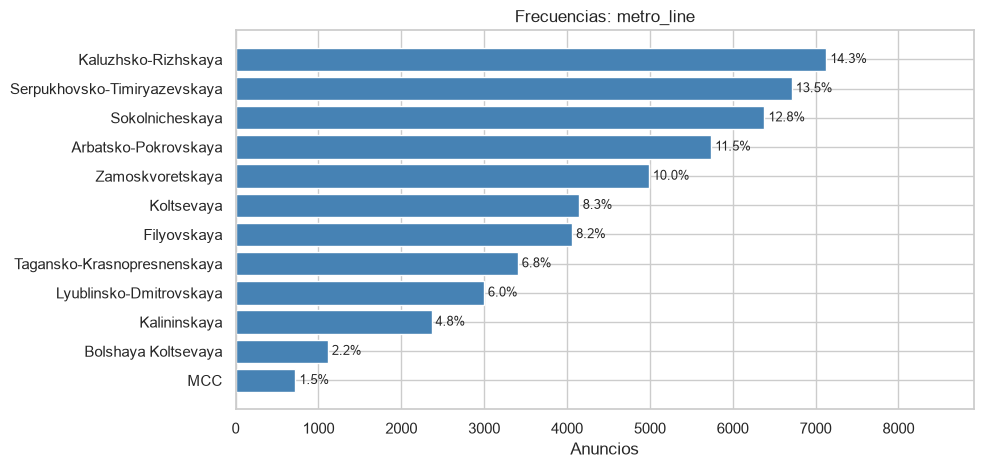

,categoria,frecuencia_absoluta,frecuencia_relativa_pct
0,transport,39577,79.55
1,walk,10176,20.45


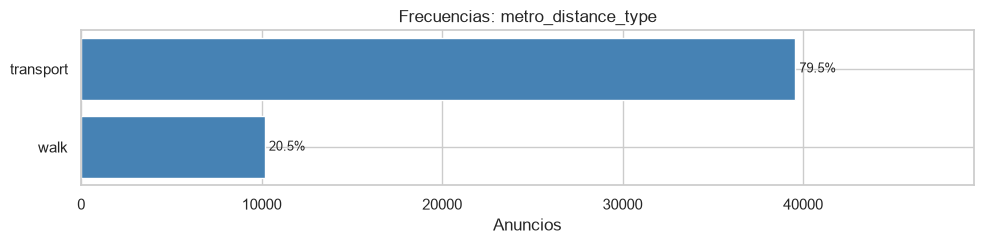

,categoria,frecuencia_absoluta,frecuencia_relativa_pct
0,agency,32542,65.41
1,owner,17211,34.59


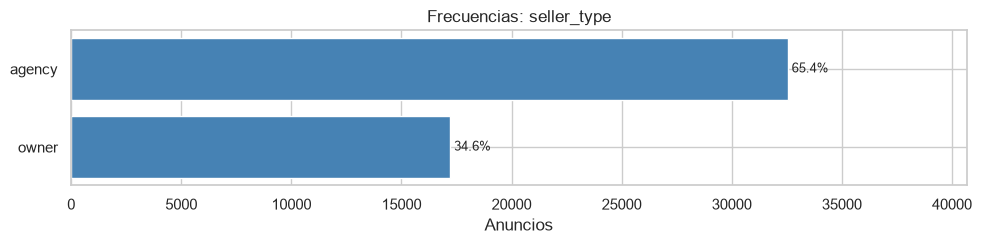

,categoria,frecuencia_absoluta,frecuencia_relativa_pct
0,True,37305,74.98
1,False,12448,25.02


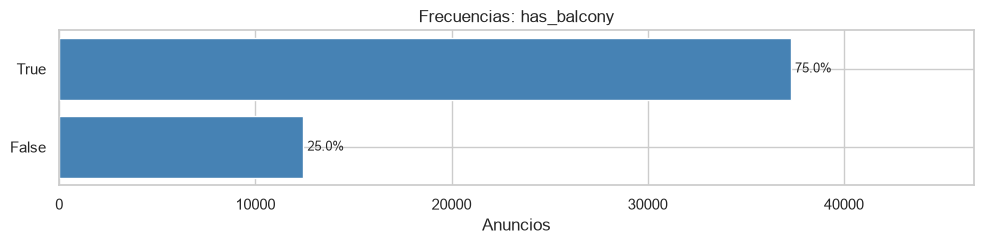

In [9]:
for variable in categoricas_uni + binarias_uni:
    vista = frecuencias_visuales[variable]
    print(variable)
    display(vista.reset_index(drop=True))
    tabla_completa = tablas_frecuencia[variable]
    grafico = tabla_completa.head(10) if len(tabla_completa) > 15 else tabla_completa
    fig, ax = plt.subplots(figsize=(10, max(2.6, .32 * len(grafico) + 1)))
    ax.barh(grafico["categoria"], grafico["frecuencia_absoluta"], color="steelblue")
    ax.invert_yaxis()
    titulo = f"Frecuencias: {variable}"
    if len(tabla_completa) > 15:
        cobertura = grafico["frecuencia_relativa_pct"].sum()
        titulo += f" | Top 10: {cobertura:.1f}% del total"
        print(f"Otras {len(tabla_completa) - 10} categorias: {100 - cobertura:.1f}% del total; incluidas en la tabla.")
    ax.set(title=titulo, xlabel="Anuncios", ylabel="")
    ax.set_xlim(0, grafico["frecuencia_absoluta"].max() * 1.25)
    for posicion, (_, fila) in enumerate(grafico.iterrows()):
        ax.text(fila["frecuencia_absoluta"], posicion,
                f" {fila['frecuencia_relativa_pct']:.1f}%", va="center", fontsize=9)
    fig.tight_layout()
    plt.show()


Publicaciones: 2020-01-01 a 2026-04-29; fechas faltantes: 0
El ultimo mes puede estar incompleto: interpretar su conteo junto al rango observado.


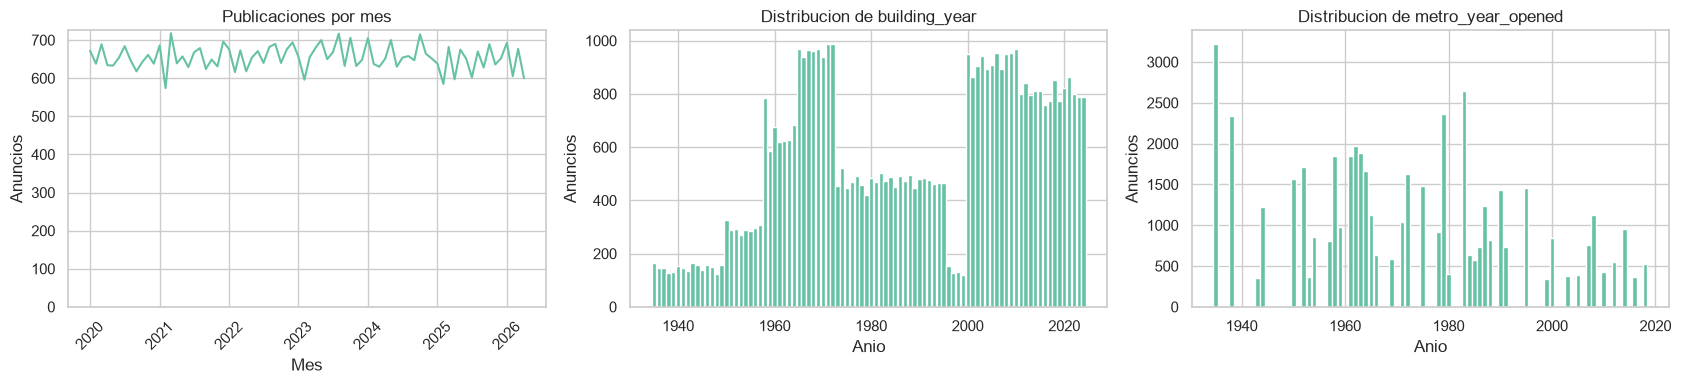

In [10]:
# La fecha y su mes derivado se estudian una sola vez y en orden cronologico.
fechas_uni = datos_univariados["date_posted_dt"]
conteos_mensuales_uni = fechas_uni.dropna().dt.to_period("M").value_counts().sort_index()
if not conteos_mensuales_uni.empty:
    calendario_uni = pd.period_range(conteos_mensuales_uni.index.min(),
                                    conteos_mensuales_uni.index.max(), freq="M")
    conteos_mensuales_uni = conteos_mensuales_uni.reindex(calendario_uni, fill_value=0)
print(f"Publicaciones: {fechas_uni.min().date()} a {fechas_uni.max().date()}; "
      f"fechas faltantes: {fechas_uni.isna().sum():,}")
print("El ultimo mes puede estar incompleto: interpretar su conteo junto al rango observado.")
fig, axes = plt.subplots(1, 3, figsize=(17, 4))
axes[0].plot(conteos_mensuales_uni.index.to_timestamp(), conteos_mensuales_uni.values)
axes[0].set(title="Publicaciones por mes", xlabel="Mes", ylabel="Anuncios")
axes[0].set_ylim(bottom=0)
axes[0].tick_params(axis="x", rotation=45)
for ax, variable in zip(axes[1:], anios_uni):
    conteos_anios = datos_univariados[variable].value_counts().sort_index()
    ax.bar(conteos_anios.index, conteos_anios.values, width=.9)
    ax.set(title=f"Distribucion de {variable}", xlabel="Anio", ylabel="Anuncios")
fig.tight_layout()
plt.show()

### 3.4. Valores atípicos y problemas de calidad

Se usa `|asimetría| > 2` como señal exploratoria de asimetría extrema y `|asimetría| > 1` como señal de asimetría elevada. Los límites de 1,5 × IQR identifican extremos estadísticos, **no errores**; se informan sin recortar las observaciones.
Las reglas físicas y temporales son comprobaciones distintas: por ejemplo, una suma de superficies superior a la superficie total o una construcción posterior a la publicación requieren revisar la fuente. Este diagnóstico no aplica correcciones adicionales a la limpieza de superficies ya realizada.

In [11]:
q1_uni = datos_univariados[numericas_uni].quantile(.25)
q3_uni = datos_univariados[numericas_uni].quantile(.75)
iqr_uni = q3_uni - q1_uni
limites_inferiores_uni = q1_uni - 1.5 * iqr_uni
limites_superiores_uni = q3_uni + 1.5 * iqr_uni
extremos_uni = (datos_univariados[numericas_uni].lt(limites_inferiores_uni)
                | datos_univariados[numericas_uni].gt(limites_superiores_uni))
diagnostico_distribuciones = pd.DataFrame({
    "asimetria": datos_univariados[numericas_uni].skew(),
    "extremos_IQR": extremos_uni.sum(),
    "extremos_pct_validos": extremos_uni.sum() / datos_univariados[numericas_uni].count() * 100,
    "IQR": iqr_uni,
})
diagnostico_distribuciones["asimetria_extrema"] = diagnostico_distribuciones["asimetria"].abs().gt(2)
atencion_distribuciones = diagnostico_distribuciones.loc[
    diagnostico_distribuciones["asimetria"].abs().gt(1)
    | diagnostico_distribuciones["extremos_IQR"].gt(0)
].sort_values("extremos_pct_validos", ascending=False)
display(atencion_distribuciones)

reglas_calidad = {}
for variable in ["total_area", "living_area", "kitchen_area", "ceiling_height", "price_rub", "price_per_sqm"]:
    reglas_calidad[f"{variable} <= 0"] = datos_univariados[variable].le(0)
for variable in ["rooms", "floor", "total_floors", "metro_distance_min", "to_center_km", "metro_to_center_km"]:
    reglas_calidad[f"{variable} < 0"] = datos_univariados[variable].lt(0)
for variable in ["rooms", "floor", "total_floors", "n_listings_secondary", "n_listings_newbuild", *anios_uni]:
    reglas_calidad[f"{variable} no entero"] = datos_univariados[variable].mod(1).ne(0) & datos_univariados[variable].notna()
reglas_calidad.update({
    "living_area + kitchen_area > total_area": (
        datos_univariados["living_area"] + datos_univariados["kitchen_area"]
        > datos_univariados["total_area"] + 1e-9
    ),
    "floor > total_floors": datos_univariados["floor"].gt(datos_univariados["total_floors"]),
    "building_year > anio de publicacion": datos_univariados["building_year"].gt(fechas_uni.dt.year),
    "metro_year_opened > anio de publicacion": datos_univariados["metro_year_opened"].gt(fechas_uni.dt.year),
    "latitud fuera de [-90, 90]": ~datos_univariados["lat"].between(-90, 90) & datos_univariados["lat"].notna(),
    "longitud fuera de [-180, 180]": ~datos_univariados["lon"].between(-180, 180) & datos_univariados["lon"].notna(),
})
resumen_reglas_calidad = pd.DataFrame([
    {"regla": nombre, "registros": int(mascara.sum()), "porcentaje_total": mascara.mean() * 100}
    for nombre, mascara in reglas_calidad.items()
])
print(f"Reglas revisadas: {len(resumen_reglas_calidad)}; "
      f"sin alertas: {resumen_reglas_calidad['registros'].eq(0).sum()}")
display(resumen_reglas_calidad.loc[resumen_reglas_calidad["registros"].gt(0)])

# Mostrar solo tres ejemplos por tipo de inconsistencia; las mascaras conservan todos.
for regla, columnas in [
    ("living_area + kitchen_area > total_area", ["id", "living_area", "kitchen_area", "total_area"]),
    ("building_year > anio de publicacion", ["id", "building_year", "date_posted_dt"]),
]:
    if reglas_calidad[regla].any():
        print(regla)
        display(datos_univariados.loc[reglas_calidad[regla], columnas].head(3))

faltantes_contexto_uni = datos_univariados.groupby("year_month")[[
    "secondary_mom_change_pct", "newbuild_mom_change_pct"
]].agg(lambda columna: columna.isna().sum())
display(faltantes_contexto_uni.loc[faltantes_contexto_uni.sum(axis=1).gt(0)])
print("Este diagnostico no aplica cambios adicionales a la limpieza de la seccion 2.2.")

Reglas revisadas: 25; sin alertas: 24
building_year > anio de publicacion
Este diagnostico no aplica cambios adicionales a la limpieza de la seccion 2.2.


,asimetria,extremos_IQR,extremos_pct_validos,IQR,asimetria_extrema
to_center_km,2.12,4644,9.33,9.03,True
metro_distance_min,2.04,3870,7.78,49.00,True
metro_lat,-0.58,3185,6.40,0.06,False
newbuild_price_per_sqm,1.23,2851,5.73,"137,100.00",False
secondary_price_per_sqm,1.22,2823,5.67,"124,600.00",False
price_per_sqm,1.69,2675,5.38,"116,600.00",False
price_rub,2.00,2452,4.93,"8,906,000.00",False
lon,-1.23,1896,3.81,0.18,False
metro_lon,0.11,1807,3.63,0.11,False
floor,1.01,1691,3.40,7.00,False


,regla,registros,porcentaje_total
21,building_year > anio de publicacion,1266,2.54


,id,building_year,date_posted_dt
5,S000006,2023,2022-01-12
25,S000026,2024,2020-12-27
34,S000035,2024,2021-12-05


,secondary_mom_change_pct,newbuild_mom_change_pct
year_month,,


### 3.5. Síntesis del análisis univariado

- **Muestra analizada:** 49,753 anuncios, después de eliminar 247 registros por superficies inconsistentes. No quedan casos con `living_area + kitchen_area > total_area`.
- **Precio:** media de 13.15 M RUB, mediana de 11.11 M RUB y asimetría positiva de 2.00. El 84.54 % cuesta hasta 20 M RUB; el máximo es 93.44 M RUB. Los precios altos pueden influir sobre futuros ajustes OLS.
- **Extremos estadísticos:** 2,452 precios (4.93 %) superan el límite superior de 1,5 × IQR (29.77 M RUB), sin extremos inferiores. Se conservan estos anuncios: no se aplicó eliminación por precio.
- **Predictoras y alertas pendientes:** `to_center_km` y `metro_distance_min` tienen asimetrías de 2.12 y 2.04. Persisten 1,266 anuncios (2.54 %) con construcción posterior al año de publicación; esta condición solo se señala. `price_per_sqm` deriva del objetivo y la superficie, y requiere atención antes de modelar.
- **Imputación y variabilidad:** se imputaron 672 faltantes por variable en `secondary_mom_change_pct` y `newbuild_mom_change_pct`, con sus medias calculadas después de la eliminación por superficies; no quedan nulos. Su origen temporal en enero de 2020 está documentado en la sección 2.2. No se detectaron columnas constantes, valores dominantes de al menos el 95 %, filas duplicadas ni IDs repetidos. El CSV integrado conserva los datos originales.


<a id="bivariado"></a>

## 4. Análisis bivariado

Relaciones individuales con `price_rub` sobre `df_venta_limpio`. Las métricas y los resúmenes utilizan todos los registros válidos; no se eliminan columnas ni se toman decisiones de selección.

### 4.1. Variables derivadas y posibles fugas de información

`price_per_sqm` utiliza el precio objetivo en su construcción: su relación no es evidencia predictiva independiente y no se incluye en la tabla de posibles predictores. Los indicadores mensuales contemporáneos se conservan con advertencias de disponibilidad y procedencia. La imputación de enero de 2020 corresponde al EDA; en una evaluación predictiva se debe ajustar solo con entrenamiento.

In [12]:
objetivo = "price_rub"
datos_bivariados = df_venta_limpio.copy(deep=True)
exclusiones_bivariadas = {
    "id": "Identificador del anuncio",
    "complex_id": "Identificador del complejo",
    "price_per_sqm": "Derivada del precio objetivo y de total_area",
    "_merge_district_prices": "Indicador tecnico de correspondencia",
    "_merge_metro_stations": "Indicador tecnico de correspondencia",
    "date_posted": "Representada mediante date_posted_dt",
    "year_month": "Representada mediante el resumen mensual de date_posted_dt",
}
control_variables_bivariado = pd.DataFrame([
    {"variables": "price_per_sqm", "precaucion": "Dependencia matematica del objetivo; no es evidencia independiente."},
    {"variables": "secondary_price_per_sqm, newbuild_price_per_sqm",
     "precaucion": "Referencias del mismo distrito/mes: revisar si incluyen estos anuncios y si estaban disponibles al publicar."},
    {"variables": "secondary_mom_change_pct, newbuild_mom_change_pct",
     "precaucion": "Cambios de indices contemporaneos; revisar construccion y disponibilidad. Enero de 2020 fue imputado."},
    {"variables": "n_listings_secondary, n_listings_newbuild",
     "precaucion": "Recuentos del mes completo; pueden incluir anuncios posteriores a la fecha de prediccion."},
    {"variables": "cbr_key_rate_pct, avg_mortgage_rate_pct, mortgage_rate_at_listing",
     "precaucion": "Verificar fecha de vigencia y disponibilidad al publicar; correlacion no demuestra fuga."},
    {"variables": "metro_lat, metro_lon, metro_year_opened, metro_to_center_km",
     "precaucion": "Catalogo de estaciones: comprobar su disponibilidad historica para el anuncio."},
])
display(control_variables_bivariado.style.set_properties(**{
    "white-space": "normal", "text-align": "left", "max-width": "600px"
}))
numericas = [c for c in datos_bivariados.select_dtypes(include="number")
             if c != objetivo and c not in exclusiones_bivariadas]
categoricas = categoricas_uni.copy()
binarias = binarias_uni.copy()
temporales = ["date_posted_dt", "building_year", "metro_year_opened"]

,variables,precaucion
0,price_per_sqm,Dependencia matematica del objetivo; no es evidencia independiente.
1,"secondary_price_per_sqm, newbuild_price_per_sqm",Referencias del mismo distrito/mes: revisar si incluyen estos anuncios y si estaban disponibles al publicar.
2,"secondary_mom_change_pct, newbuild_mom_change_pct",Cambios de indices contemporaneos; revisar construccion y disponibilidad. Enero de 2020 fue imputado.
3,"n_listings_secondary, n_listings_newbuild",Recuentos del mes completo; pueden incluir anuncios posteriores a la fecha de prediccion.
4,"cbr_key_rate_pct, avg_mortgage_rate_pct, mortgage_rate_at_listing",Verificar fecha de vigencia y disponibilidad al publicar; correlacion no demuestra fuga.
5,"metro_lat, metro_lon, metro_year_opened, metro_to_center_km",Catalogo de estaciones: comprobar su disponibilidad historica para el anuncio.


### 4.2. Características numéricas y precio

Pearson, Spearman y R² se calculan con todos los pares finitos disponibles. R² corresponde al ajuste lineal simple con intercepto (equivale a Pearson²). Los años se incluyen en las métricas y se visualizan como cohortes en el análisis temporal.
Los seis gráficos cubren superficie, distancias, habitaciones, una referencia contextual y una variable de asociación débil, sin repetir las referencias de precios o las distintas superficies. La dispersión usa una muestra aleatoria de hasta 5.000 anuncios (`random_state=42`); rectas y medianas usan todos los pares. Una asociación débil no descarta relaciones no lineales ni contribuciones conjuntas.

,variable,n,Pearson_r,Spearman_rho,R2,pendiente_RUB_por_unidad,brecha_abs_rho_r
13,secondary_price_per_sqm,"49,753",0.792,0.790,0.628,54.65,-0.003
14,newbuild_price_per_sqm,"49,753",0.791,0.788,0.625,49.43,-0.003
11,to_center_km,"49,753",-0.534,-0.680,0.285,"-359,313.48",0.146
10,metro_distance_min,"49,753",-0.497,-0.653,0.247,"-78,132.64",0.156
2,total_area,"49,753",0.396,0.418,0.157,"197,048.08",0.022
3,living_area,"49,753",0.383,0.406,0.146,"293,596.41",0.024
5,rooms,"49,753",0.353,0.365,0.125,"2,958,650.52",0.012
0,lat,"49,753",0.266,0.263,0.071,"15,833,104.68",-0.003
1,lon,"49,753",0.224,0.224,0.050,"10,640,592.42",-0.000
4,kitchen_area,"49,753",0.196,0.197,0.038,"588,403.81",0.001


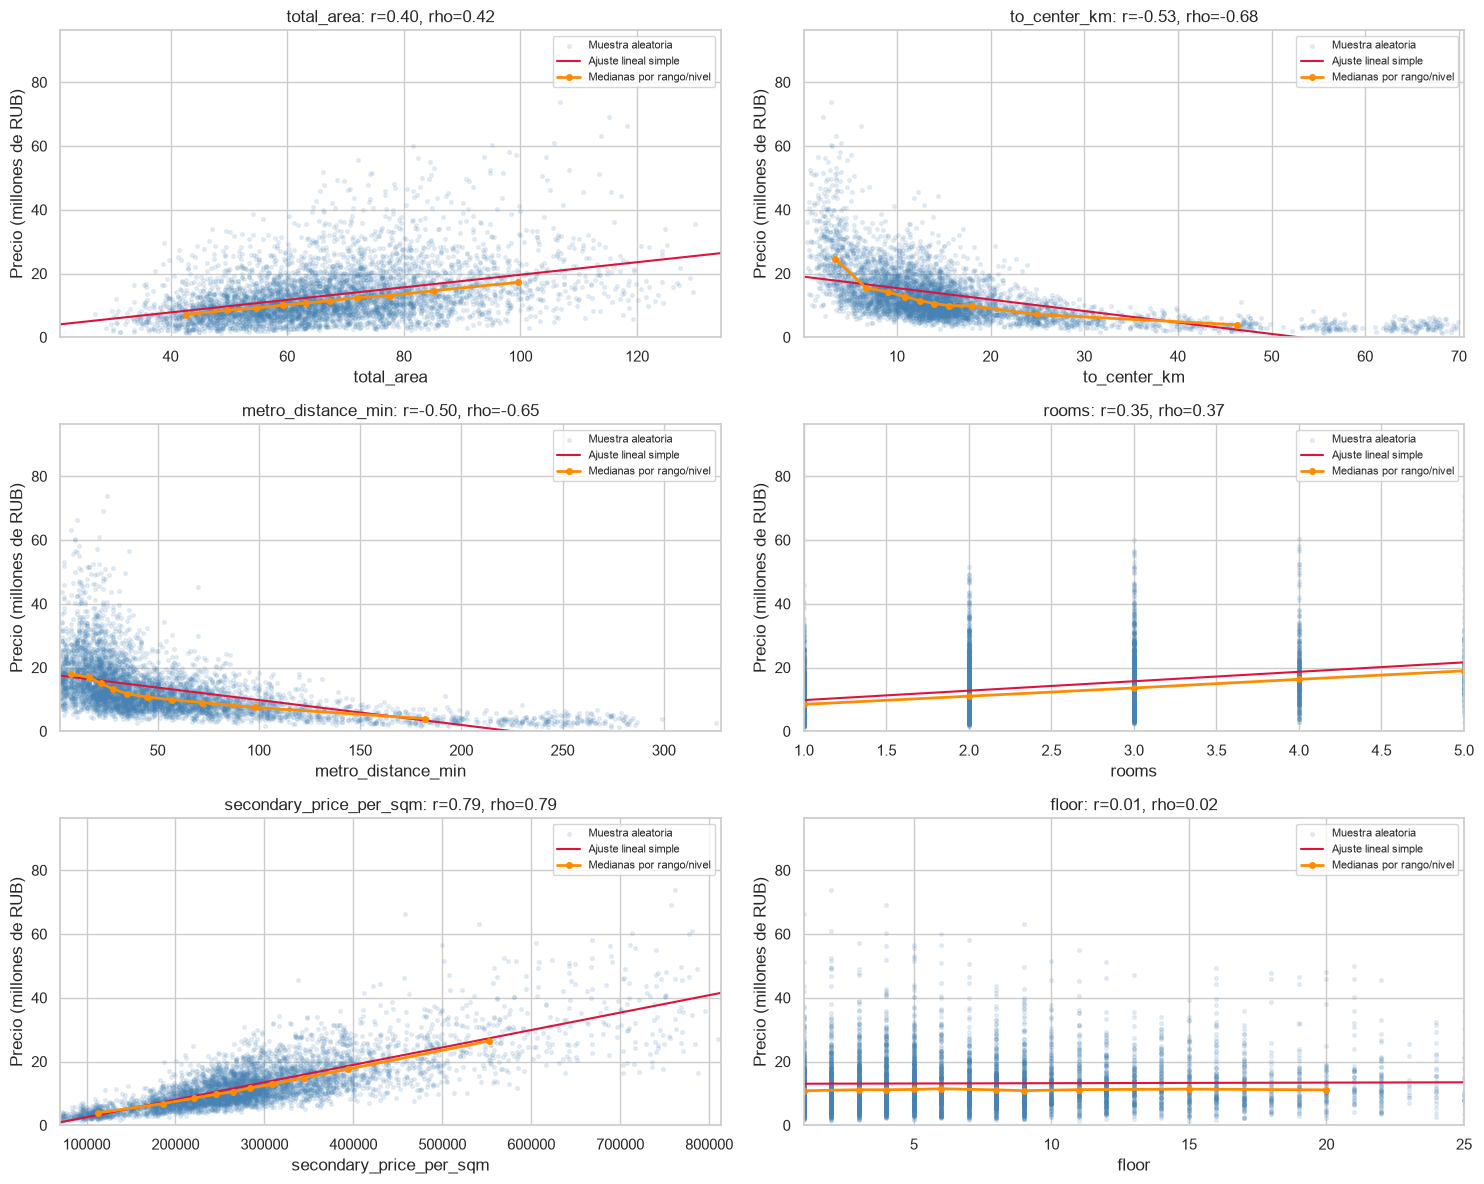

In [13]:
resultados_regresiones = []
for variable in numericas:
    pares = datos_bivariados[[variable, objetivo]].dropna()
    pares = pares.loc[np.isfinite(pares).all(axis=1)]
    fila = {"variable": variable, "n": len(pares), "Pearson_r": np.nan,
            "Spearman_rho": np.nan, "R2": np.nan,
            "pendiente_RUB_por_unidad": np.nan, "intercepto_RUB": np.nan}
    if len(pares) >= 3 and pares[variable].nunique() > 1 and pares[objetivo].nunique() > 1:
        ajuste = linregress(pares[variable], pares[objetivo])
        fila.update(Pearson_r=ajuste.rvalue,
                    Spearman_rho=pares[variable].corr(pares[objetivo], method="spearman"),
                    R2=ajuste.rvalue ** 2,
                    pendiente_RUB_por_unidad=ajuste.slope, intercepto_RUB=ajuste.intercept)
    resultados_regresiones.append(fila)
resultados_regresiones = pd.DataFrame(resultados_regresiones)
resultados_regresiones["brecha_abs_rho_r"] = (
    resultados_regresiones["Spearman_rho"].abs() - resultados_regresiones["Pearson_r"].abs()
)
resultados_regresiones = resultados_regresiones.sort_values("Pearson_r", key=abs, ascending=False)
display(resultados_regresiones.drop(columns="intercepto_RUB").style.format({
    "n": "{:,.0f}", "Pearson_r": "{:.3f}", "Spearman_rho": "{:.3f}", "R2": "{:.3f}",
    "brecha_abs_rho_r": "{:.3f}", "pendiente_RUB_por_unidad": "{:,.2f}"
}))

variables_graficadas = ["total_area", "to_center_km", "metro_distance_min", "rooms",
                       "secondary_price_per_sqm", "floor"]
muestra_dispersion = datos_bivariados.sample(n=min(5000, len(datos_bivariados)), random_state=42)
perfiles_numericos_bivariados = {}
fig, axes = plt.subplots(3, 2, figsize=(15, 12))
for ax, variable in zip(axes.flat, variables_graficadas):
    pares = datos_bivariados[[variable, objetivo]].dropna()
    pares = pares.loc[np.isfinite(pares).all(axis=1)]
    muestra = muestra_dispersion[[variable, objetivo]].dropna()
    muestra = muestra.loc[np.isfinite(muestra).all(axis=1)]
    ax.scatter(muestra[variable], muestra[objetivo] / 1e6, s=7, alpha=.12,
               color="steelblue", rasterized=True, label="Muestra aleatoria")
    metrica = resultados_regresiones.set_index("variable").loc[variable]
    x = np.array([pares[variable].min(), pares[variable].max()])
    ax.plot(x, (metrica["intercepto_RUB"] + metrica["pendiente_RUB_por_unidad"] * x) / 1e6,
            color="crimson", label="Ajuste lineal simple")
    # Medianas sobre datos completos: niveles discretos o diez rangos de igual frecuencia.
    clave = pares[variable] if pares[variable].nunique() <= 12 else pd.qcut(pares[variable], 10, duplicates="drop")
    perfil = pares.groupby(clave, observed=True).agg(
        x_mediana=(variable, "median"), precio_mediano=(objetivo, "median"), n=(objetivo, "size")
    ).sort_values("x_mediana")
    perfiles_numericos_bivariados[variable] = perfil
    ax.plot(perfil["x_mediana"], perfil["precio_mediano"] / 1e6, "o-", color="darkorange",
            linewidth=2, markersize=4, label="Medianas por rango/nivel")
    ax.set(title=f"{variable}: r={metrica['Pearson_r']:.2f}, rho={metrica['Spearman_rho']:.2f}",
           xlabel=variable, ylabel="Precio (millones de RUB)",
           xlim=(pares[variable].min(), pares[variable].max()), ylim=(0, datos_bivariados[objetivo].max() / 1e6 * 1.03))
    ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

### 4.3. Características categóricas y precio

Todos los grupos participan en los cálculos de cantidad, media y mediana. Para `district` y `metro_station`, se muestran las cinco medianas más bajas y las cinco más altas; `resumen_grupos` conserva las tablas completas ordenadas. Sus gráficos muestran las doce categorías con más anuncios, ordenadas por mediana, con cobertura y tamaños explícitos. Los boxplots conservan los valores extremos.

district: 129 categorias; tabla ordenada por mediana
okrug: 11 categorias; tabla ordenada por mediana
building_type: 6 categorias; tabla ordenada por mediana
renovation: 4 categorias; tabla ordenada por mediana
metro_station: 104 categorias; tabla ordenada por mediana
metro_line: 12 categorias; tabla ordenada por mediana
metro_distance_type: 2 categorias; tabla ordenada por mediana
seller_type: 2 categorias; tabla ordenada por mediana


,n,precio_medio,precio_mediano
district,,,
Kievsky,398,"3,556,587.94","3,328,500.00"
Klyonovskoye,411,"3,522,746.96","3,334,000.00"
Novofyodorovskoye,390,"3,617,638.46","3,398,000.00"
Rogovskoye,349,"3,600,438.40","3,426,000.00"
Shchapovskoye,384,"3,775,971.35","3,469,000.00"
Yakimanka,378,"32,202,470.90","30,385,000.00"
Presnensky,393,"33,452,687.02","30,906,000.00"
Arbat,398,"35,014,364.32","32,478,500.00"
Tverskoy,393,"35,129,066.16","33,936,000.00"


,n,precio_medio,precio_mediano
okrug,,,
TAO,3929,"3,854,972.26","3,619,000.00"
ZelAO,357,"6,033,378.15","5,728,000.00"
NAO,4146,"6,781,794.50","6,260,000.00"
YuAO,6192,"11,247,416.83","10,208,500.00"
SVAO,6632,"11,245,413.60","10,338,500.00"
VAO,6066,"11,699,321.96","10,763,500.00"
SAO,5835,"13,076,122.88","11,811,000.00"
SZAO,3400,"14,978,507.65","13,878,000.00"
ZAO,4590,"16,130,002.40","14,530,500.00"


,n,precio_medio,precio_mediano
building_type,,,
khrushchev,7490,"11,115,754.61","9,486,500.00"
panel,10090,"12,064,921.21","10,136,500.00"
modern_panel,9922,"13,079,524.49","11,066,500.00"
brick,8802,"13,686,820.38","11,618,500.00"
monolith,9947,"14,256,890.02","12,191,000.00"
stalin,3502,"16,341,643.35","13,780,000.00"


,n,precio_medio,precio_mediano
renovation,,,
no_renovation,9991,"11,083,894.81","9,439,000.00"
cosmetic,19947,"12,423,324.81","10,535,000.00"
euro,14898,"14,346,896.83","12,242,500.00"
designer,4917,"16,675,389.47","14,322,000.00"


,n,precio_medio,precio_mediano
metro_station,,,
Yuzhnaya,568,"9,294,570.42","8,602,000.00"
Pechatniki,355,"9,789,366.20","8,710,000.00"
Kozhukhovskaya,358,"10,348,650.84","9,012,000.00"
Tekstilshchiki,315,"10,067,638.10","9,372,000.00"
Kantemirovskaya,631,"10,116,250.40","9,441,000.00"
Shchukinskaya,740,"14,553,641.89","13,477,000.00"
Universitet,577,"15,263,573.66","13,533,000.00"
Novye Cheryomushki,782,"14,580,445.01","13,668,000.00"
Sokol,716,"14,478,585.20","13,688,000.00"


,n,precio_medio,precio_mediano
metro_line,,,
MCC,722,"11,575,128.81","9,749,500.00"
Lyublinsko-Dmitrovskaya,2997,"12,252,863.86","10,054,000.00"
Kalininskaya,2364,"12,159,708.54","10,523,500.00"
Serpukhovsko-Timiryazevskaya,6712,"12,730,660.46","10,843,500.00"
Filyovskaya,4061,"13,316,307.56","10,953,000.00"
Bolshaya Koltsevaya,1113,"12,454,733.15","11,106,000.00"
Zamoskvoretskaya,4987,"13,014,916.78","11,205,000.00"
Arbatsko-Pokrovskaya,5739,"12,648,653.60","11,251,000.00"
Kaluzhsko-Rizhskaya,7129,"12,895,443.54","11,389,000.00"


,n,precio_medio,precio_mediano
metro_distance_type,,,
transport,39577,"11,501,471.99","9,921,000.00"
walk,10176,"19,564,313.58","17,070,500.00"


,n,precio_medio,precio_mediano
seller_type,,,
owner,17211,"13,157,193.77","11,065,000.00"
agency,32542,"13,147,063.79","11,135,500.00"


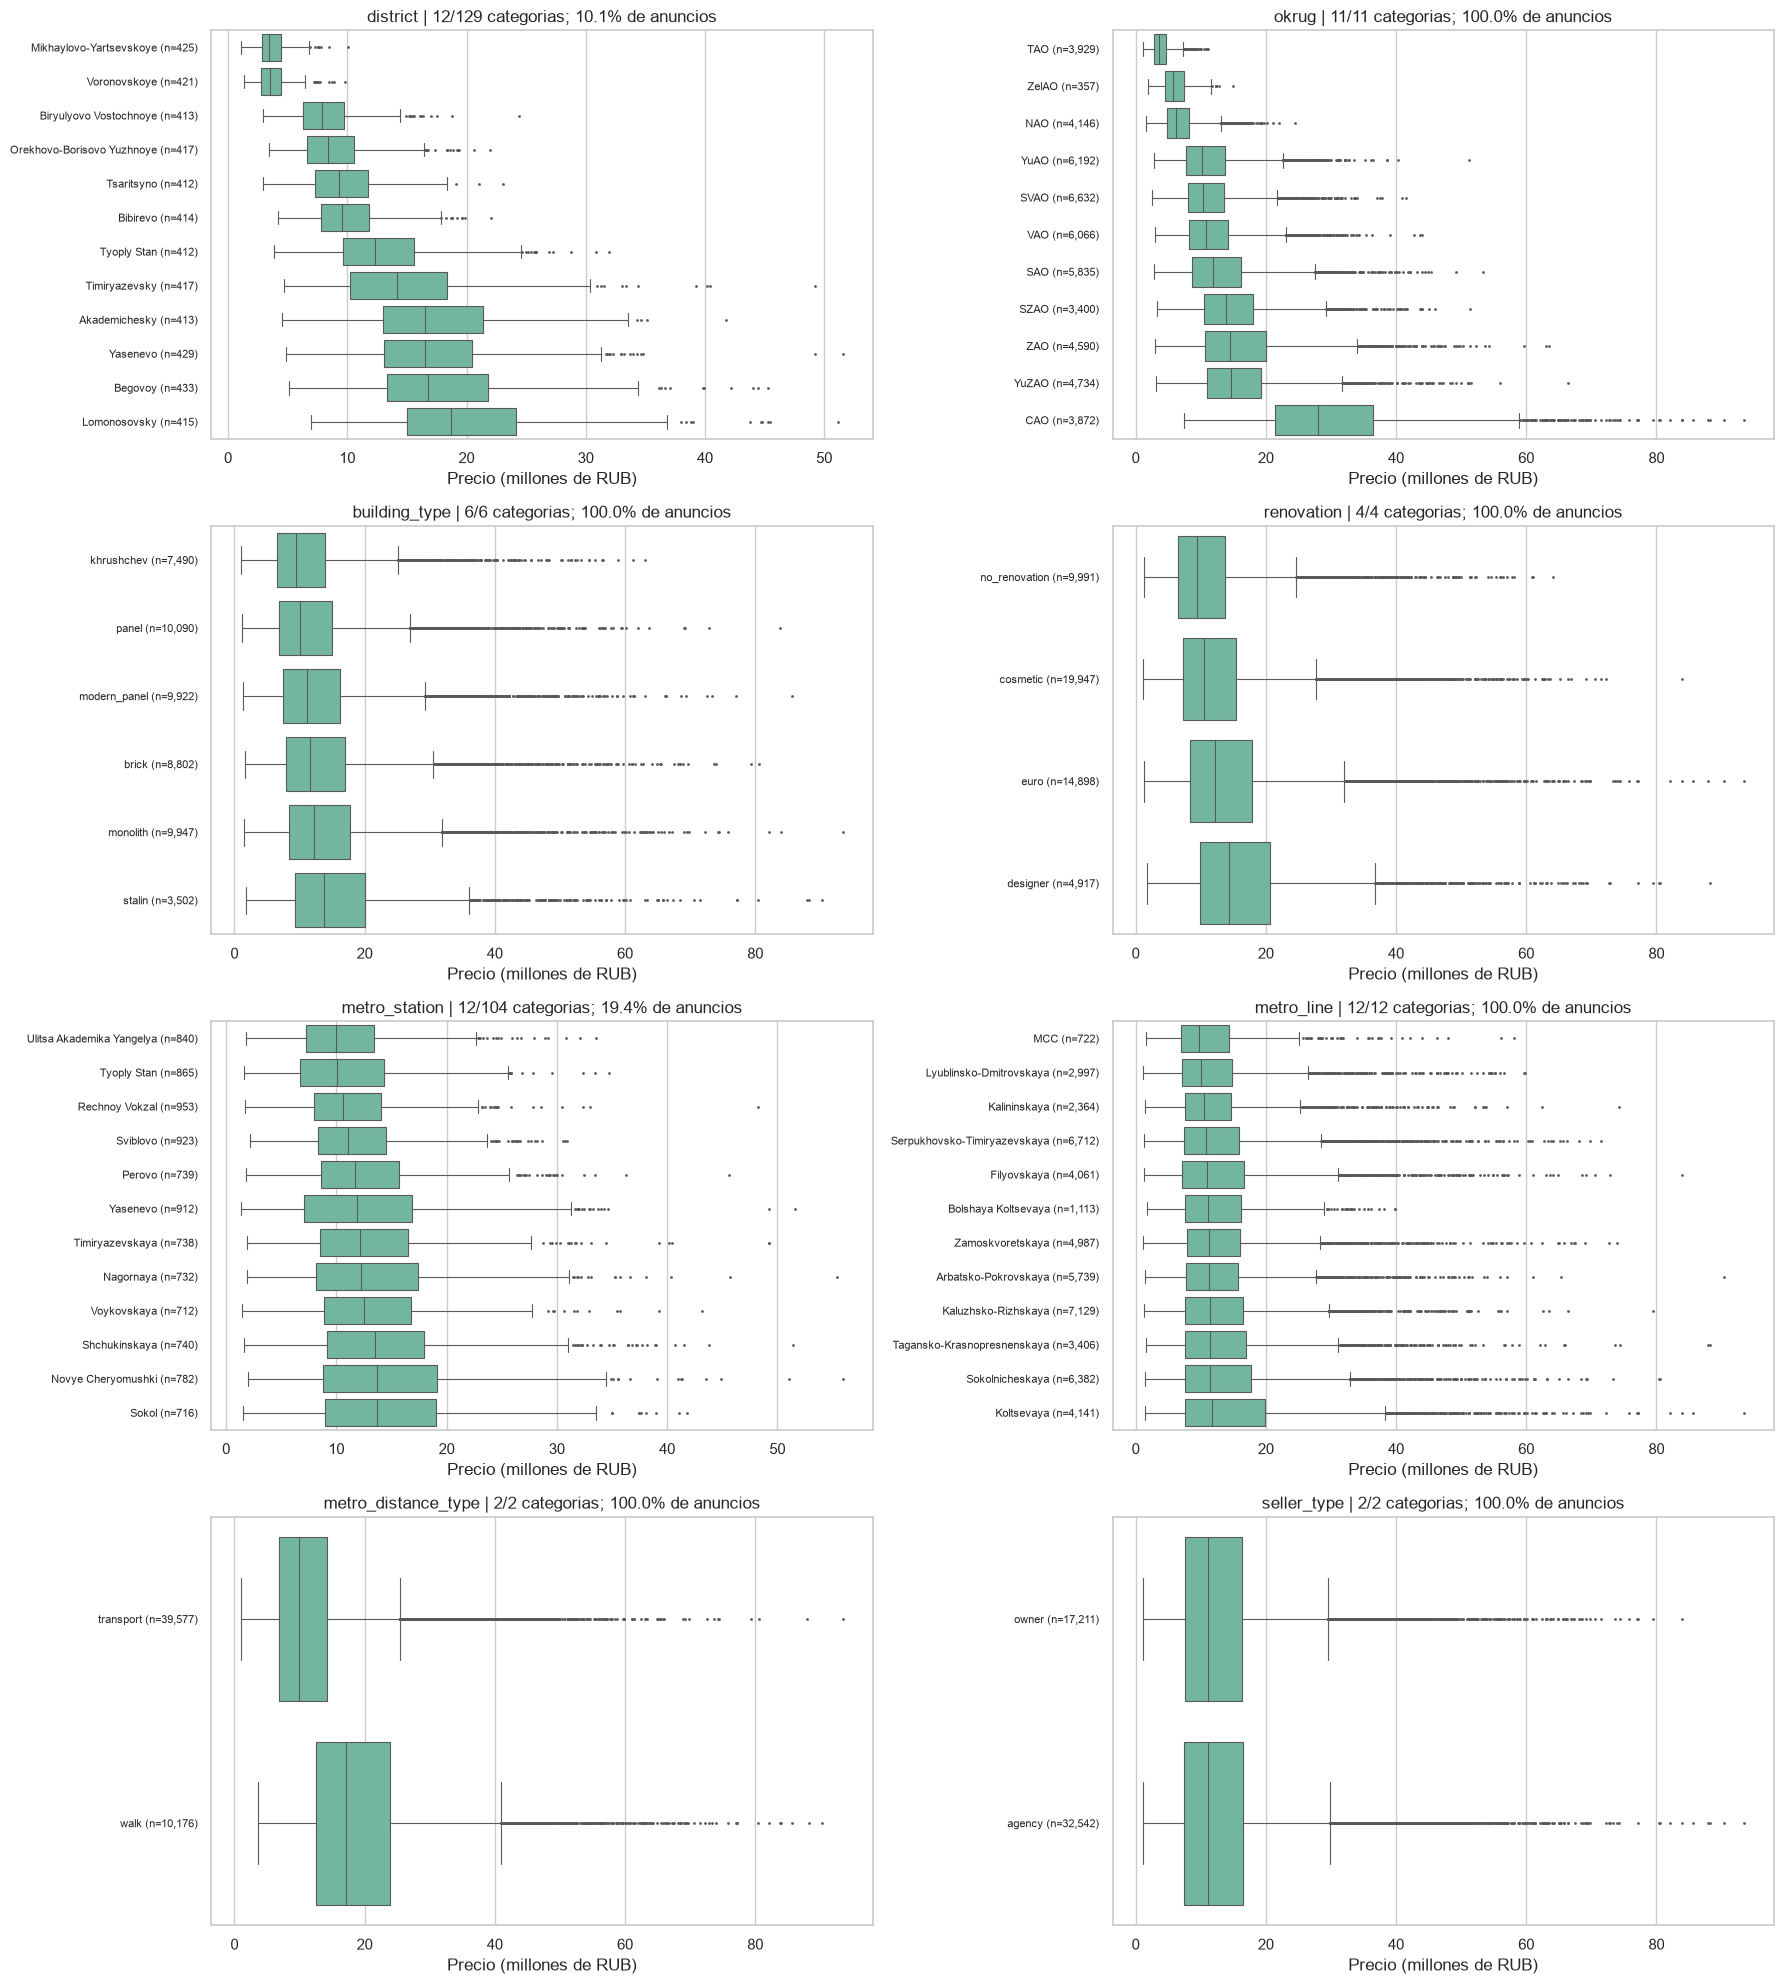

In [14]:
resumen_grupos = {}
resumen_diferencias_categoricas = []
categorias_graficadas = {}
for variable in categoricas:
    grupos = datos_bivariados.groupby(variable, observed=True, dropna=False)[objetivo].agg(
        n="count", precio_medio="mean", precio_mediano="median"
    ).sort_values("precio_mediano")
    resumen_grupos[variable] = grupos
    bajo, alto = grupos.iloc[0], grupos.iloc[-1]
    resumen_diferencias_categoricas.append({
        "variable": variable, "categorias": len(grupos), "n_minimo_grupo": grupos["n"].min(),
        "categoria_menor_mediana": grupos.index[0], "mediana_min_RUB": bajo["precio_mediano"],
        "n_grupo_min": bajo["n"], "categoria_mayor_mediana": grupos.index[-1],
        "mediana_max_RUB": alto["precio_mediano"], "n_grupo_max": alto["n"],
    })
    print(f"{variable}: {len(grupos)} categorias; tabla ordenada por mediana")
    vista = pd.concat([grupos.head(5), grupos.tail(5)]) if len(grupos) > 15 else grupos
    display(vista)
    frecuentes = grupos.nlargest(12, "n").sort_values("precio_mediano") if len(grupos) > 15 else grupos
    categorias_graficadas[variable] = frecuentes
resumen_diferencias_categoricas = pd.DataFrame(resumen_diferencias_categoricas)

fig, axes = plt.subplots(4, 2, figsize=(18, 20))
for ax, variable in zip(axes.flat, categoricas):
    frecuentes = categorias_graficadas[variable]
    orden = frecuentes.index.tolist()
    plot_data = datos_bivariados.loc[datos_bivariados[variable].isin(orden), [variable, objetivo]].copy()
    plot_data["precio_millones_RUB"] = plot_data[objetivo] / 1e6
    sns.boxplot(data=plot_data, y=variable, x="precio_millones_RUB", order=orden,
                orient="h", fliersize=1, linewidth=.8, ax=ax)
    ax.set_yticks(range(len(orden)), labels=[f"{c} (n={int(frecuentes.loc[c, 'n']):,})" for c in orden])
    cobertura = frecuentes["n"].sum() / len(datos_bivariados) * 100
    ax.set(title=f"{variable} | {len(orden)}/{len(resumen_grupos[variable])} categorias; {cobertura:.1f}% de anuncios",
           xlabel="Precio (millones de RUB)", ylabel="")
    ax.tick_params(axis="y", labelsize=8)
fig.tight_layout()
plt.show()

### 4.4. Características binarias y precio

Se comparan presencia y ausencia de balcón mediante cantidades, medias, medianas y distribuciones. Las diferencias son descriptivas y pueden reflejar otras características de las propiedades; no estiman un efecto causal aislado.

,n,precio_medio,precio_mediano
has_balcony,,,
False,12448,"12,873,741.32","10,913,000.00"
True,37305,"13,242,940.09","11,176,000.00"


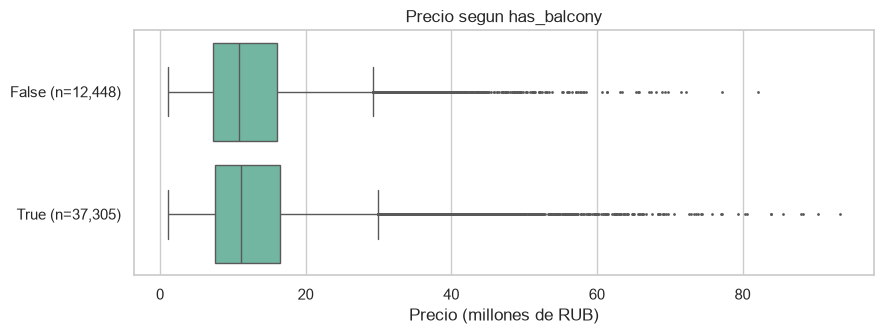

In [15]:
resumen_binarias = {}
fig, axes = plt.subplots(1, len(binarias), figsize=(9 * len(binarias), 3.5), squeeze=False)
for ax, variable in zip(axes.flat, binarias):
    grupos = datos_bivariados.groupby(variable, observed=True, dropna=False)[objetivo].agg(
        n="count", precio_medio="mean", precio_mediano="median"
    ).sort_index()
    resumen_binarias[variable] = grupos
    display(grupos)
    plot_data = datos_bivariados[[variable, objetivo]].copy()
    plot_data["precio_millones_RUB"] = plot_data[objetivo] / 1e6
    sns.boxplot(data=plot_data, y=variable, x="precio_millones_RUB", order=grupos.index.tolist(),
                orient="h", fliersize=1, ax=ax)
    ax.set_yticks(range(len(grupos)), labels=[f"{valor} (n={int(grupos.loc[valor, 'n']):,})" for valor in grupos.index])
    ax.set(title=f"Precio segun {variable}", xlabel="Precio (millones de RUB)", ylabel="")
fig.tight_layout()
plt.show()

### 4.5. Publicación y características temporales

Se usa la mediana mensual con el número de publicaciones por período. Las cuatro mayores variaciones absolutas entre medianas mensuales y la mayor caída se señalan como períodos a revisar, sin declararlas anomalías ni cambios estructurales. El último mes puede ser parcial.
Los anuncios de cada mes corresponden a propiedades distintas: cambios de composición pueden alterar las medianas; no se sigue el precio de una misma vivienda. Los años de construcción e inauguración se comparan como cohortes, no como evolución del mercado. Los anuncios con construcción posterior a su publicación siguen presentes y señalados en el univariado.

Inicio y fin del periodo observado
Mayores cambios mensuales absolutos de la mediana


,n,precio_mediano,precio_medio,variacion_mediana_pct
2020-01,672,"7,915,500.00","9,269,430.06",NaN
2026-04,600,"13,315,500.00","15,341,756.67",8.41


,n,precio_mediano,precio_medio,variacion_mediana_pct
2020-09,618,"9,376,500.00","10,912,283.17",8.78
2020-11,661,"9,537,000.00","10,998,727.69",8.28
2023-03,655,"11,848,000.00","13,847,726.72",9.06
2025-03,682,"12,151,000.00","14,264,164.22",-7.79
2026-04,600,"13,315,500.00","15,341,756.67",8.41


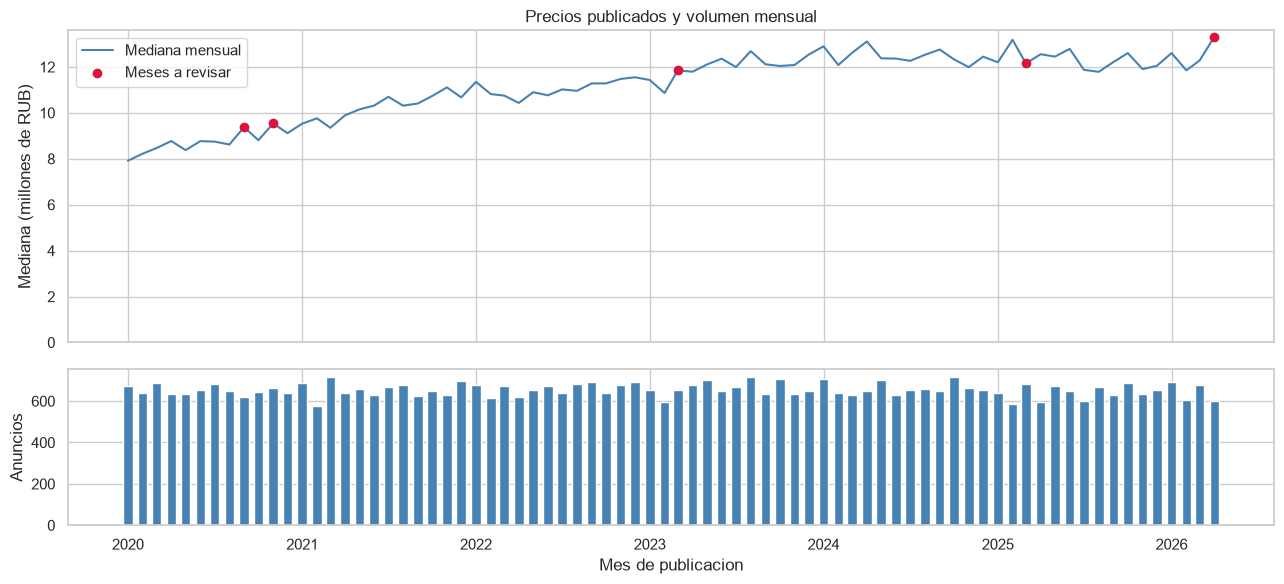

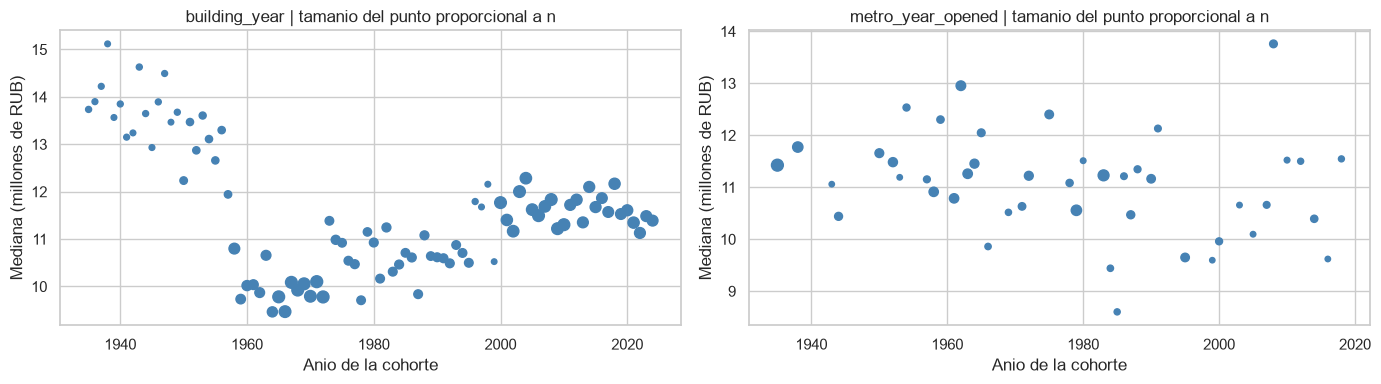

In [16]:
mes_publicacion = datos_bivariados["date_posted_dt"].dt.to_period("M")
evolucion_mensual = datos_bivariados.groupby(mes_publicacion, observed=True)[objetivo].agg(
    n="count", precio_mediano="median", precio_medio="mean"
).sort_index()
calendario = pd.period_range(evolucion_mensual.index.min(), evolucion_mensual.index.max(), freq="M")
evolucion_mensual = evolucion_mensual.reindex(calendario)
evolucion_mensual["n"] = evolucion_mensual["n"].fillna(0).astype(int)
evolucion_mensual["variacion_mediana_pct"] = evolucion_mensual["precio_mediano"].pct_change(fill_method=None) * 100
meses_a_revisar = evolucion_mensual["variacion_mediana_pct"].abs().nlargest(4).index.union(
    pd.PeriodIndex([evolucion_mensual["variacion_mediana_pct"].idxmin()])
)
periodos_a_revisar = evolucion_mensual.loc[meses_a_revisar].sort_index()
print("Inicio y fin del periodo observado")
display(evolucion_mensual.iloc[[0, -1]])
print("Mayores cambios mensuales absolutos de la mediana")
display(periodos_a_revisar)

fig, axes = plt.subplots(2, 1, figsize=(13, 6), sharex=True, gridspec_kw={"height_ratios": [2, 1]})
x = evolucion_mensual.index.to_timestamp()
axes[0].plot(x, evolucion_mensual["precio_mediano"] / 1e6, label="Mediana mensual", color="steelblue")
axes[0].scatter(periodos_a_revisar.index.to_timestamp(), periodos_a_revisar["precio_mediano"] / 1e6,
                color="crimson", label="Meses a revisar", zorder=3)
axes[0].set(ylabel="Mediana (millones de RUB)", title="Precios publicados y volumen mensual", ylim=(0, None))
axes[0].legend()
axes[1].bar(x, evolucion_mensual["n"], width=20, color="steelblue")
axes[1].set(xlabel="Mes de publicacion", ylabel="Anuncios")
fig.tight_layout()
plt.show()

# Cohortes: se conserva el conteo de cada anio para interpretar medianas con pocos casos.
evoluciones_temporales = {"date_posted_dt": evolucion_mensual}
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for ax, variable in zip(axes, ["building_year", "metro_year_opened"]):
    cohorte = datos_bivariados.groupby(variable, observed=True)[objetivo].agg(n="count", precio_mediano="median").sort_index()
    evoluciones_temporales[variable] = cohorte
    ax.scatter(cohorte.index, cohorte["precio_mediano"] / 1e6,
               s=cohorte["n"] / cohorte["n"].max() * 65 + 8, color="steelblue")
    ax.set(title=f"{variable} | tamanio del punto proporcional a n",
           xlabel="Anio de la cohorte", ylabel="Mediana (millones de RUB)")
fig.tight_layout()
plt.show()

<a id="resumen-bivariado"></a>

### 4.6. Síntesis del análisis bivariado

- **Numéricas:** las referencias distritales `secondary_price_per_sqm` (Pearson 0.792, Spearman 0.790) y `newbuild_price_per_sqm` (0.791 y 0.788) muestran las asociaciones individuales positivas más altas, sujetas a las advertencias de procedencia y disponibilidad. `total_area` tiene Pearson 0.396 (R² 0.157): sus medianas por rango muestran un crecimiento aproximadamente lineal, con amplia dispersión individual. Las medianas por número de habitaciones también aumentan.
- **Forma de las relaciones:** `to_center_km` (Pearson -0.534; Spearman -0.680) y `metro_distance_min` (-0.497; -0.653) presentan asociaciones decrecientes más marcadas por rangos. Sus perfiles de medianas cambian de pendiente y una sola recta resume imperfectamente la forma observada. En `floor` (Pearson 0.012; Spearman 0.017) no se aprecia una tendencia global fuerte; esto no descarta aportes conjuntos con otras variables.
- **Categorías:** la mediana va de 3.33 M RUB en Kievsky (n=398) a 35.11 M RUB en Khamovniki (n=389); por okrug, de 3.62 M en TAO a 28.05 M en CAO. También hay diferencias por renovación (9.44–14.32 M RUB) y tipo de edificio (9.49–13.78 M). Todos los grupos de distrito tienen al menos 339 anuncios; son comparaciones sin ajustar por superficie, localización u otras características.
- **Balcón:** medianas de 10.91 M RUB sin balcón (n=12,448) y 11.18 M con balcón (n=37,305); diferencia descriptiva de 2.41 %, sin interpretación causal.
- **Tiempo:** la mediana mensual pasa de 7.92 M RUB en 2020-01 (n=672) a 13.32 M en 2026-04 (n=600), una diferencia nominal de 68.22 %. El ascenso inicial da paso a oscilaciones: el mayor aumento mensual es 9.06 % en 2023-03 y la mayor caída -7.79 % en 2025-03. Son distintos anuncios en cada período y el último mes puede ser parcial; no se identifica una revalorización de la misma vivienda ni un cambio estructural confirmado.
- **Precauciones para modelar:** `price_per_sqm` depende matemáticamente del objetivo. Las referencias, variaciones y volúmenes mensuales requieren revisar construcción, disponibilidad temporal e inclusión de anuncios de la muestra. La correlación individual no determina qué variables serán mejores en OLS; la utilidad predictiva deberá evaluarse mediante selección y validación posteriores. No se seleccionaron características ni se alteraron los datos.


<a id="correlacion"></a>

## 5. Matriz de correlación y multicolinealidad

[Volver al indice](#indice)

Pearson se calcula sobre pares disponibles; se muestra tambien su cantidad de observaciones. Se incluyen variables binarias (0/1) y anios numericos. Se excluyen IDs y la variable derivada del objetivo. El umbral exploratorio es |r| >= 0,80 entre predictores. Una correlacion elevada puede reflejar informacion redundante y dificultar interpretar coeficientes en futuros modelos multiples; no demuestra por si sola multicolinealidad completa. VIF y seleccion se evaluaran despues. Los indicadores mensuales compartidos por distrito/mes repiten contexto entre anuncios: las filas no son observaciones independientes de ese contexto.

,lat,lon,total_area,living_area,kitchen_area,rooms,floor,total_floors,building_year,ceiling_height,has_balcony,metro_distance_min,to_center_km,price_rub,mortgage_rate_at_listing,secondary_price_per_sqm,newbuild_price_per_sqm,secondary_mom_change_pct,newbuild_mom_change_pct,n_listings_secondary,n_listings_newbuild,cbr_key_rate_pct,avg_mortgage_rate_pct,metro_lat,metro_lon,metro_year_opened,metro_to_center_km
lat,1.00,0.46,0.00,0.00,-0.00,-0.00,0.01,0.00,-0.00,0.00,-0.00,-0.62,-0.70,0.27,0.00,0.36,0.36,-0.00,0.00,0.00,-0.00,0.00,0.00,0.41,0.04,-0.07,-0.09
lon,0.46,1.00,-0.00,0.00,0.00,-0.00,0.01,0.00,-0.00,0.00,0.00,-0.65,-0.71,0.22,0.01,0.27,0.27,0.00,0.00,0.01,-0.02,0.01,0.01,0.06,0.36,-0.04,-0.04
total_area,0.00,-0.00,1.00,0.96,0.48,0.89,-0.00,-0.00,-0.00,0.00,-0.00,-0.00,-0.00,0.40,-0.00,0.00,0.00,-0.00,-0.00,0.00,-0.00,-0.00,-0.00,0.00,0.00,-0.00,0.00
living_area,0.00,0.00,0.96,1.00,0.47,0.86,-0.00,-0.00,-0.00,0.00,-0.00,-0.01,-0.00,0.38,-0.00,0.00,0.00,-0.00,-0.00,0.00,-0.00,-0.00,-0.00,0.01,-0.00,-0.01,-0.00
kitchen_area,-0.00,0.00,0.48,0.47,1.00,0.54,-0.01,0.00,0.00,-0.01,-0.00,-0.01,-0.00,0.20,0.00,0.00,0.00,0.00,0.00,-0.00,-0.00,0.00,0.00,-0.00,-0.00,-0.00,0.00
rooms,-0.00,-0.00,0.89,0.86,0.54,1.00,-0.00,-0.00,-0.00,0.00,-0.00,-0.00,0.00,0.35,0.00,0.00,0.00,-0.00,-0.00,0.00,-0.00,0.00,0.00,0.00,-0.00,-0.00,0.00
floor,0.01,0.01,-0.00,-0.00,-0.01,-0.00,1.00,0.59,-0.00,-0.00,0.01,-0.01,-0.01,0.01,0.00,0.00,0.00,0.01,0.01,-0.00,0.00,0.00,0.00,0.00,0.00,0.00,-0.00
total_floors,0.00,0.00,-0.00,-0.00,0.00,-0.00,0.59,1.00,-0.01,0.00,0.01,-0.00,-0.00,0.01,0.00,0.00,0.00,0.01,0.01,-0.00,0.01,0.00,0.00,0.01,0.00,-0.00,-0.00
building_year,-0.00,-0.00,-0.00,-0.00,0.00,-0.00,-0.00,-0.01,1.00,-0.27,-0.00,0.00,0.01,0.02,-0.00,-0.01,-0.01,-0.01,-0.00,0.00,0.00,-0.00,-0.00,0.01,-0.00,0.00,0.00
ceiling_height,0.00,0.00,0.00,0.00,-0.01,0.00,-0.00,0.00,-0.27,1.00,-0.00,-0.01,-0.01,0.07,-0.00,0.01,0.01,-0.01,-0.00,0.01,0.01,-0.00,-0.00,-0.01,-0.00,0.00,-0.00


,lat,lon,total_area,living_area,kitchen_area,rooms,floor,total_floors,building_year,ceiling_height,has_balcony,metro_distance_min,to_center_km,price_rub,mortgage_rate_at_listing,secondary_price_per_sqm,newbuild_price_per_sqm,secondary_mom_change_pct,newbuild_mom_change_pct,n_listings_secondary,n_listings_newbuild,cbr_key_rate_pct,avg_mortgage_rate_pct,metro_lat,metro_lon,metro_year_opened,metro_to_center_km
lat,49753,49753,49753,49753,49753,49753,49753,49753,49753,49753,49753,49753,49753,49753,49753,49753,49753,49753,49753,49753,49753,49753,49753,49753,49753,49753,49753
lon,49753,49753,49753,49753,49753,49753,49753,49753,49753,49753,49753,49753,49753,49753,49753,49753,49753,49753,49753,49753,49753,49753,49753,49753,49753,49753,49753
total_area,49753,49753,49753,49753,49753,49753,49753,49753,49753,49753,49753,49753,49753,49753,49753,49753,49753,49753,49753,49753,49753,49753,49753,49753,49753,49753,49753
living_area,49753,49753,49753,49753,49753,49753,49753,49753,49753,49753,49753,49753,49753,49753,49753,49753,49753,49753,49753,49753,49753,49753,49753,49753,49753,49753,49753
kitchen_area,49753,49753,49753,49753,49753,49753,49753,49753,49753,49753,49753,49753,49753,49753,49753,49753,49753,49753,49753,49753,49753,49753,49753,49753,49753,49753,49753
rooms,49753,49753,49753,49753,49753,49753,49753,49753,49753,49753,49753,49753,49753,49753,49753,49753,49753,49753,49753,49753,49753,49753,49753,49753,49753,49753,49753
floor,49753,49753,49753,49753,49753,49753,49753,49753,49753,49753,49753,49753,49753,49753,49753,49753,49753,49753,49753,49753,49753,49753,49753,49753,49753,49753,49753
total_floors,49753,49753,49753,49753,49753,49753,49753,49753,49753,49753,49753,49753,49753,49753,49753,49753,49753,49753,49753,49753,49753,49753,49753,49753,49753,49753,49753
building_year,49753,49753,49753,49753,49753,49753,49753,49753,49753,49753,49753,49753,49753,49753,49753,49753,49753,49753,49753,49753,49753,49753,49753,49753,49753,49753,49753
ceiling_height,49753,49753,49753,49753,49753,49753,49753,49753,49753,49753,49753,49753,49753,49753,49753,49753,49753,49753,49753,49753,49753,49753,49753,49753,49753,49753,49753


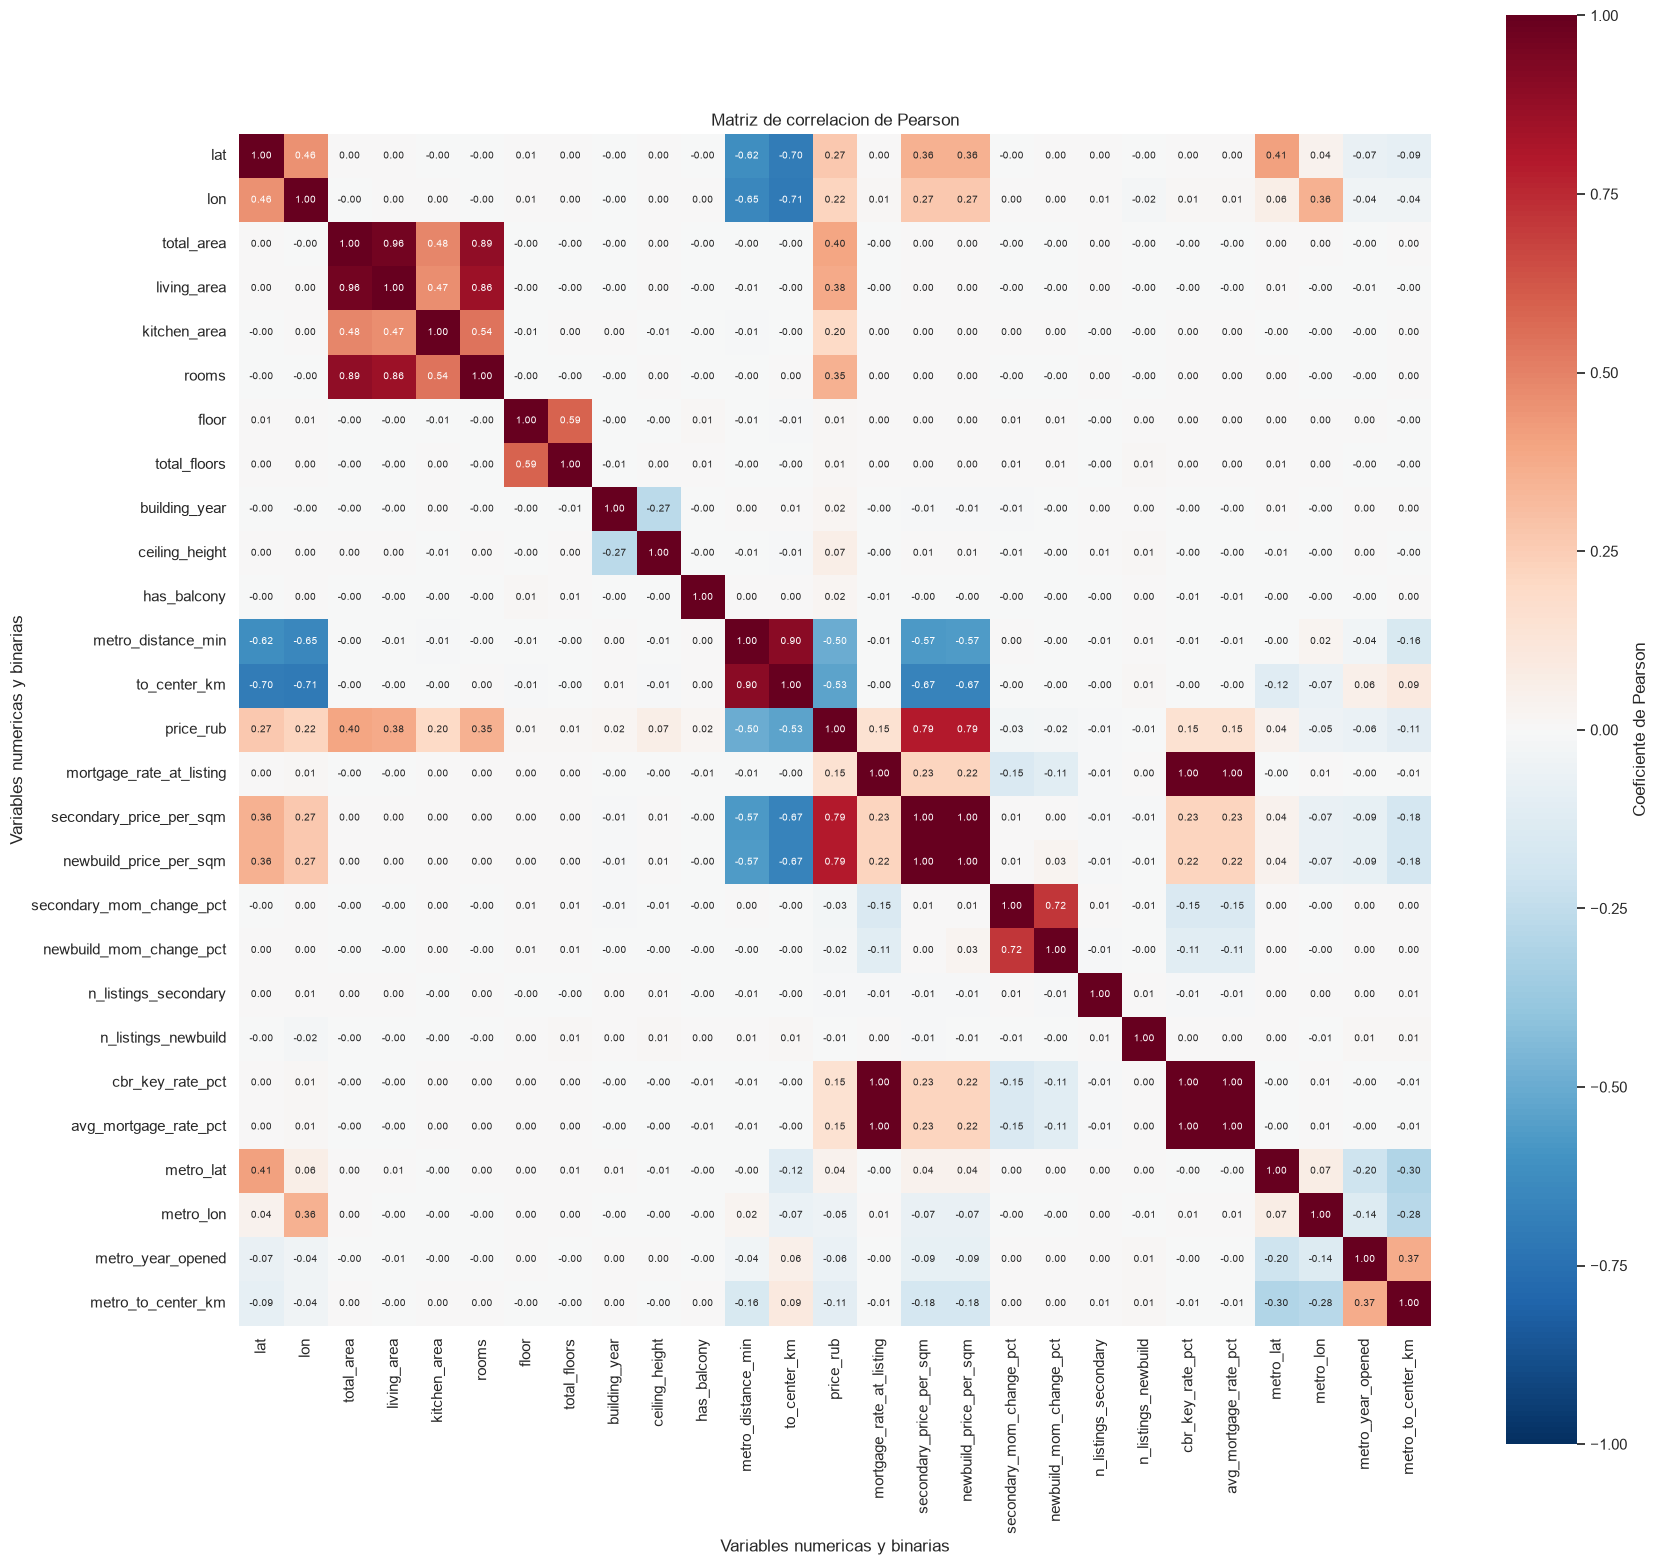

,variable_1,variable_2,Pearson_r,n_pares,ambas_del_join
5,mortgage_rate_at_listing,avg_mortgage_rate_pct,1.00,49753,False
7,cbr_key_rate_pct,avg_mortgage_rate_pct,1.00,49753,True
4,mortgage_rate_at_listing,cbr_key_rate_pct,1.00,49753,False
6,secondary_price_per_sqm,newbuild_price_per_sqm,1.00,49753,True
0,total_area,living_area,0.96,49753,False
3,metro_distance_min,to_center_km,0.90,49753,False
1,total_area,rooms,0.89,49753,False
2,living_area,rooms,0.86,49753,False


,variable_1,variable_2,Pearson_r,n_pares,ambas_del_join
7,cbr_key_rate_pct,avg_mortgage_rate_pct,1.00,49753,True
6,secondary_price_per_sqm,newbuild_price_per_sqm,1.00,49753,True


In [17]:
variables_correlacion = [c for c in datos_bivariados.select_dtypes(include=["number", "bool"]) if c not in exclusiones_bivariadas]
matriz_correlacion = datos_bivariados[variables_correlacion].corr(method="pearson")
conteos_pares = datos_bivariados[variables_correlacion].notna().astype(int).T.dot(datos_bivariados[variables_correlacion].notna().astype(int))
display(matriz_correlacion)
display(conteos_pares)
fig, ax = plt.subplots(figsize=(max(14, len(variables_correlacion) * .65), max(12, len(variables_correlacion) * .6)))
sns.heatmap(matriz_correlacion, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1, square=True, annot_kws={"size": 7}, ax=ax, cbar_kws={"label": "Coeficiente de Pearson"})
ax.set(title="Matriz de correlacion de Pearson", xlabel="Variables numericas y binarias", ylabel="Variables numericas y binarias")
fig.tight_layout()
plt.show()
columnas_join = set(district_sales_columns + metro_added_columns)
pares_altos = []
for i, a in enumerate(variables_correlacion):
    for b in variables_correlacion[i + 1:]:
        r = matriz_correlacion.loc[a, b]
        if objetivo not in (a, b) and pd.notna(r) and abs(r) >= .80:
            pares_altos.append({"variable_1": a, "variable_2": b, "Pearson_r": r, "n_pares": conteos_pares.loc[a, b], "ambas_del_join": a in columnas_join and b in columnas_join})
pares_correlacion_alta = pd.DataFrame(pares_altos, columns=["variable_1", "variable_2", "Pearson_r", "n_pares", "ambas_del_join"])
if not pares_correlacion_alta.empty:
    pares_correlacion_alta = pares_correlacion_alta.loc[pares_correlacion_alta.Pearson_r.abs().sort_values(ascending=False).index]
display(pares_correlacion_alta)
display(pares_correlacion_alta.loc[pares_correlacion_alta.ambas_del_join])


**Multicolinealidad perfecta entre las tasas de interés**

Se identificó una correlación perfecta (r = 1) entre `cbr_key_rate_pct`, `avg_mortgage_rate_pct` y `mortgage_rate_at_listing`. Esto ocurre porque las variables mantienen una relación matemática exacta: `avg_mortgage_rate_pct = cbr_key_rate_pct + 2.5`, mientras que `mortgage_rate_at_listing` es idéntica a `avg_mortgage_rate_pct`.

Esta redundancia genera **multicolinealidad perfecta**, lo que impide que OLS estime de manera única los coeficientes individuales de estas variables y dificulta su interpretación, sin aportar información predictiva adicional.


<a id="analisis-temporal"></a>

## 6. Análisis temporal de precios, estacionalidad y autocorrelación

Se usa `df_venta_limpio` sin alterar sus valores ni el CSV integrado. La unidad temporal es el **mes agregado**, no el anuncio individual. Se estudian precios nominales de propiedades distintas: pueden influir la composición de la oferta y el volumen mensual. No se estiman modelos predictivos ni se crean particiones de datos.

### 6.1. Evolución mensual de precios y precio por m²

Se cubre enero de 2020–abril de 2026. La media móvil es la media aritmética de las **tres últimas medianas mensuales**, sin completar los dos primeros períodos. Abril de 2026 termina en la última fecha observada y puede ser parcial.

76 meses; 49,753 anuncios; ultima publicacion: 2026-04-29


,media_rub,mediana_rub,anuncios,media_sqm,mediana_sqm,MM3_rub,MM3_sqm,cambio_mediana_rub_pct
date_posted_dt,,,,,,,,
2020-01-01,"9,269,430.06","7,915,500.00",672,"139,437.35","120,050.00",NaN,NaN,NaN
2026-04-01,"15,341,756.67","13,315,500.00",600,"228,057.83","199,250.00","12,481,833.33","191,016.67",8.41


,mediana_rub,anuncios,cambio_mediana_rub_pct
2020-09-01,"9,376,500.00",618,8.78
2020-11-01,"9,537,000.00",661,8.28
2023-03-01,"11,848,000.00",655,9.06
2025-03-01,"12,151,000.00",682,-7.79
2026-04-01,"13,315,500.00",600,8.41


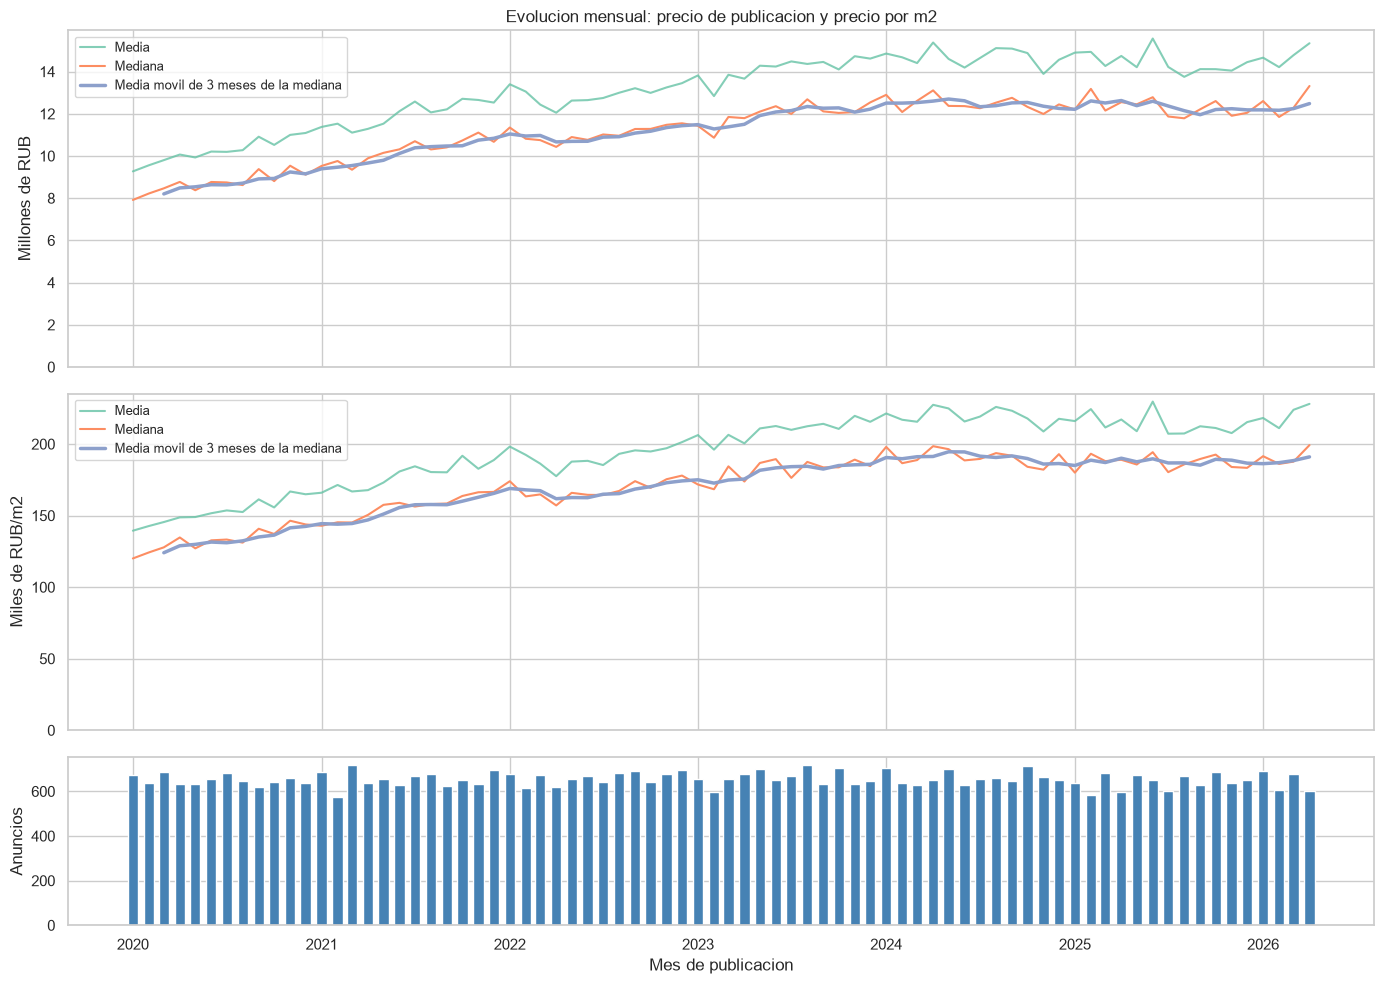

In [18]:
datos_temporales = df_venta_limpio[["date_posted_dt", "price_rub", "price_per_sqm"]].copy()
if datos_temporales["date_posted_dt"].isna().any():
    raise ValueError("Hay fechas faltantes: revisar antes de construir la serie temporal.")
if not np.isfinite(datos_temporales[["price_rub", "price_per_sqm"]]).all().all():
    raise ValueError("Hay precios no finitos: revisar sin imputar automaticamente la serie.")
mes_temporal = datos_temporales["date_posted_dt"].dt.to_period("M")
series_mensuales = datos_temporales.groupby(mes_temporal, observed=True).agg(
    media_rub=("price_rub", "mean"), mediana_rub=("price_rub", "median"),
    anuncios=("price_rub", "size"), media_sqm=("price_per_sqm", "mean"),
    mediana_sqm=("price_per_sqm", "median"),
).sort_index()
calendario_temporal = pd.period_range("2020-01", "2026-04", freq="M")
if not series_mensuales.index.equals(calendario_temporal):
    raise ValueError("La cobertura no coincide con los 76 meses esperados; no se interpolan meses.")
series_mensuales.index = series_mensuales.index.to_timestamp()
series_mensuales = series_mensuales.asfreq("MS")
for variable in ["rub", "sqm"]:
    series_mensuales[f"MM3_{variable}"] = series_mensuales[f"mediana_{variable}"].rolling(3, min_periods=3).mean()
series_mensuales["cambio_mediana_rub_pct"] = series_mensuales["mediana_rub"].pct_change(fill_method=None) * 100
print(f"{len(series_mensuales)} meses; {series_mensuales['anuncios'].sum():,} anuncios; "
      f"ultima publicacion: {datos_temporales['date_posted_dt'].max().date()}")
# La tabla completa queda en series_mensuales; se muestran extremos y cambios destacados.
display(series_mensuales.iloc[[0, -1]])
meses_destacados_temporales = series_mensuales["cambio_mediana_rub_pct"].abs().nlargest(4).index.union(
    pd.DatetimeIndex([series_mensuales["cambio_mediana_rub_pct"].idxmin()])
)
display(series_mensuales.loc[meses_destacados_temporales, ["mediana_rub", "anuncios", "cambio_mediana_rub_pct"]])
fig, axes = plt.subplots(3, 1, figsize=(14, 10), sharex=True, gridspec_kw={"height_ratios": [2, 2, 1]})
for ax, variable, escala, unidad in [(axes[0], "rub", 1e6, "Millones de RUB"), (axes[1], "sqm", 1e3, "Miles de RUB/m2")]:
    ax.plot(series_mensuales.index, series_mensuales[f"media_{variable}"] / escala, label="Media", alpha=.8)
    ax.plot(series_mensuales.index, series_mensuales[f"mediana_{variable}"] / escala, label="Mediana")
    ax.plot(series_mensuales.index, series_mensuales[f"MM3_{variable}"] / escala, label="Media movil de 3 meses de la mediana", linewidth=2.5)
    ax.set(ylabel=unidad, ylim=(0, None))
    ax.legend(fontsize=9)
axes[0].set_title("Evolucion mensual: precio de publicacion y precio por m2")
axes[2].bar(series_mensuales.index, series_mensuales["anuncios"], width=20, color="steelblue")
axes[2].set(ylabel="Anuncios", xlabel="Mes de publicacion")
fig.tight_layout()
plt.show()

**Lectura:** la mediana pasa de 7.92 a 13.32 M RUB (68.22 % nominal); la media permanece por encima de la mediana, coherente con la cola de precios altos. El crecimiento inicial se modera y aparecen oscilaciones desde 2023. Los mayores cambios de la mediana son 9.06 % en 2023-03 y -7.79 % en 2025-03; son períodos a revisar, no errores ni rupturas confirmadas.

El precio mediano por m² sube de 120,050 a 199,250 RUB/m² (65.97 %). Por tanto, el ascenso no aparece solo en el precio total. Estos agregados no aíslan inflación, localización ni cambios en la composición de las propiedades; abril de 2026 es parcial (última publicación: 2026-04-29).

### 6.2. Estacionalidad y descomposición STL

Se comparan todos los meses de enero a diciembre. El boxplot reúne anuncios de distintos años y puede mezclar tendencia con estacionalidad; las líneas anuales permiten distinguirlos. La línea de **2026 es parcial (enero–abril)**.

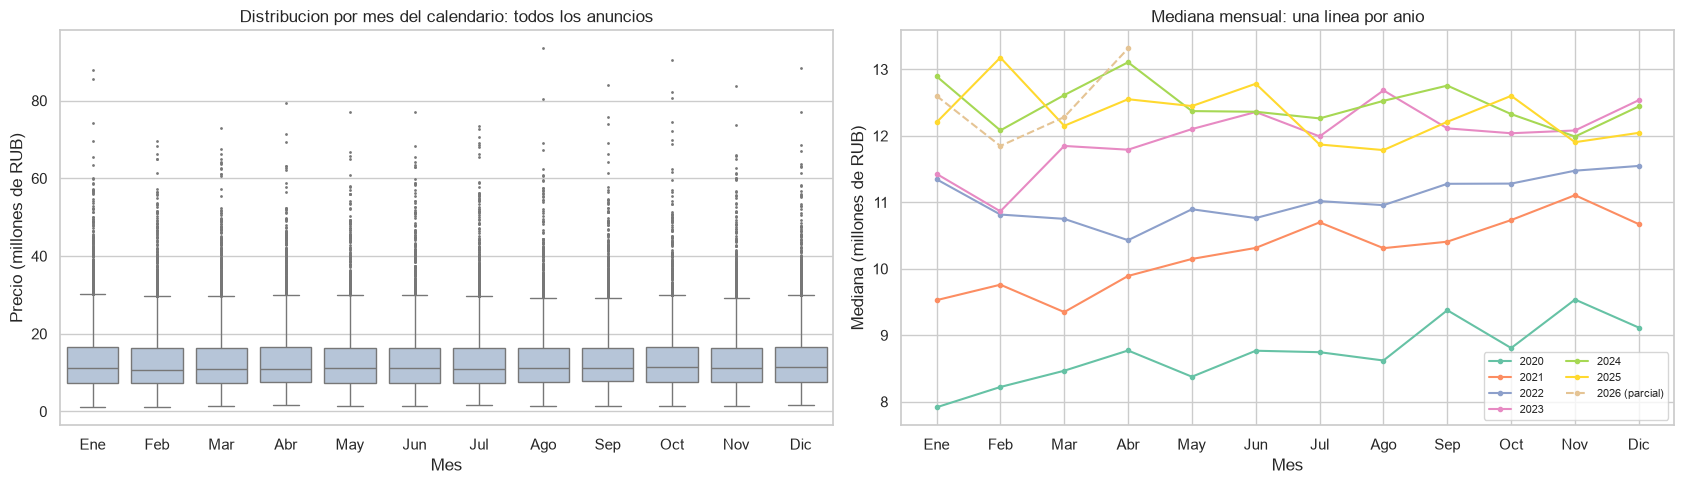

In [19]:
meses_es = ["Ene", "Feb", "Mar", "Abr", "May", "Jun", "Jul", "Ago", "Sep", "Oct", "Nov", "Dic"]
calendario_anual = series_mensuales.assign(anio=series_mensuales.index.year, mes=series_mensuales.index.month)
medianas_por_anio = calendario_anual.pivot(index="mes", columns="anio", values="mediana_rub").reindex(range(1, 13))
fig, axes = plt.subplots(1, 2, figsize=(17, 5))
vista_estacional = datos_temporales.assign(
    mes=datos_temporales["date_posted_dt"].dt.month,
    precio_millones=datos_temporales["price_rub"] / 1e6,
)
sns.boxplot(data=vista_estacional, x="mes", y="precio_millones", order=list(range(1, 13)),
            fliersize=1, color="lightsteelblue", ax=axes[0])
axes[0].set(title="Distribucion por mes del calendario: todos los anuncios", xlabel="Mes", ylabel="Precio (millones de RUB)")
for anio in medianas_por_anio:
    parcial = medianas_por_anio[anio].count() < 12
    axes[1].plot(medianas_por_anio.index, medianas_por_anio[anio] / 1e6, marker="o", markersize=3,
                 linestyle="--" if parcial else "-", label=f"{anio}" + (" (parcial)" if parcial else ""))
axes[1].set(title="Mediana mensual: una linea por anio", xlabel="Mes", ylabel="Mediana (millones de RUB)")
axes[0].set_xticks(range(12), labels=meses_es)
axes[1].set_xticks(range(1, 13), labels=meses_es)
axes[1].legend(fontsize=8, ncol=2)
fig.tight_layout()
plt.show()

**Lectura:** las líneas anuales se separan principalmente por nivel y los máximos no se repiten en un mismo mes de todos los años. El boxplot sin ajustar no permite atribuir las diferencias a estacionalidad: enero–abril incluye también 2026 y cada mes mezcla propiedades y años distintos. La comparación siguiente elimina el nivel anual y, por separado, la tendencia suave; excluye 2026 únicamente de las comparaciones entre años completos, sin eliminar sus anuncios del dataset ni de STL.

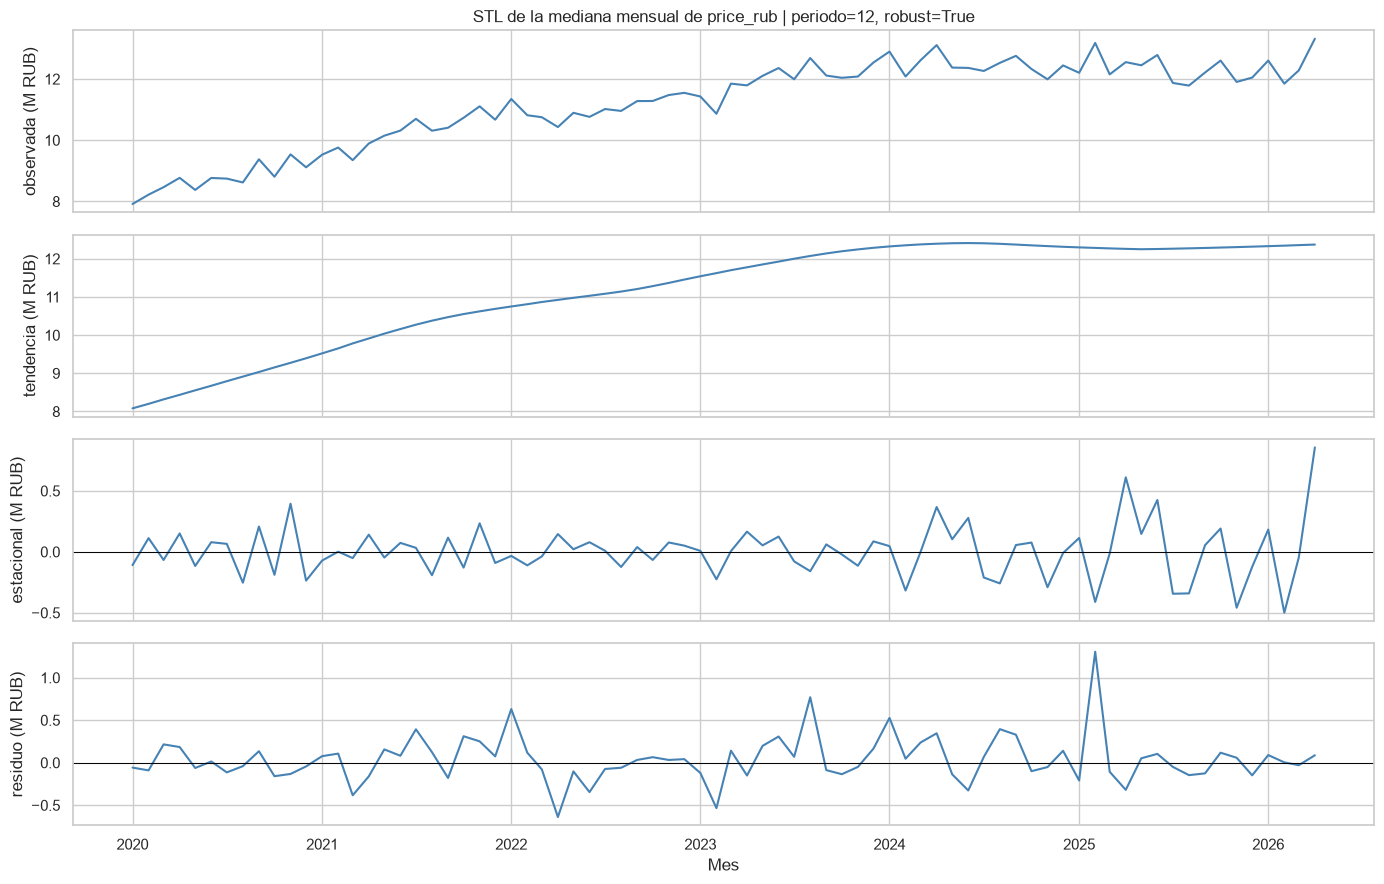

,anios,desvio_anual_medio_pct,desvio_tendencia_mediano_pct,anios_sobre_tendencia,componente_STL_medio_pct,desvio_sqm_mediano_pct
Ene,6,-2.63,-0.36,3,-0.17,-1.85
Feb,6,-3.01,0.16,4,-1.25,-0.77
Mar,6,-2.63,0.14,3,-0.29,0.39
Abr,6,-0.52,1.26,4,2.32,0.24
May,6,-0.85,0.41,3,0.14,1.52
Jun,6,0.77,1.30,4,1.52,1.45
Jul,6,-0.14,-0.57,1,-0.67,-1.42
Ago,6,0.09,-1.15,2,-2.00,-0.35
Sep,6,2.27,0.21,3,0.86,1.16
Oct,6,1.57,-0.10,2,-0.31,-0.91


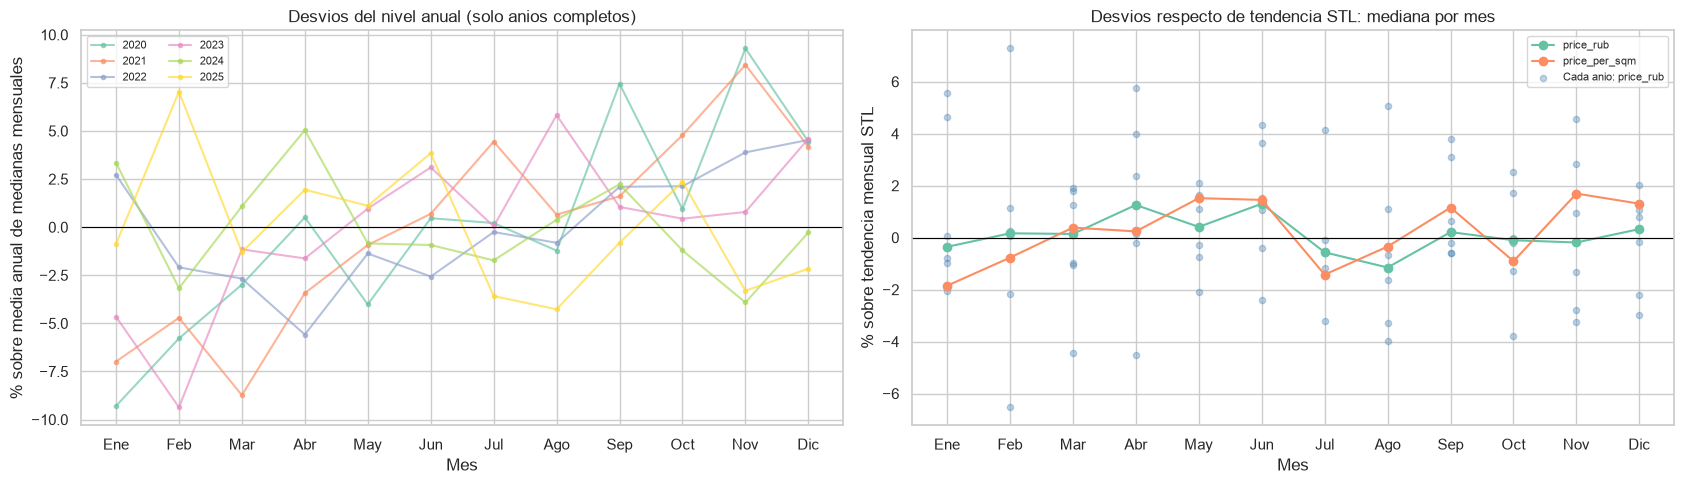

In [20]:
# STL es una descomposicion exploratoria, no una prediccion ni una transformacion del dataset.
stl_precio = STL(series_mensuales["mediana_rub"], period=12, robust=True).fit()
stl_sqm = STL(series_mensuales["mediana_sqm"], period=12, robust=True).fit()
componentes_stl = pd.DataFrame({
    "observada": series_mensuales["mediana_rub"], "tendencia": stl_precio.trend,
    "estacional": stl_precio.seasonal, "residuo": stl_precio.resid,
})
fig, axes = plt.subplots(4, 1, figsize=(14, 9), sharex=True)
for ax, columna in zip(axes, componentes_stl):
    ax.plot(componentes_stl.index, componentes_stl[columna] / 1e6, color="steelblue")
    ax.set(ylabel=f"{columna} (M RUB)")
    if columna in ["estacional", "residuo"]:
        ax.axhline(0, color="black", linewidth=.7)
axes[0].set_title("STL de la mediana mensual de price_rub | periodo=12, robust=True")
axes[-1].set_xlabel("Mes")
fig.tight_layout()
plt.show()

# Solo anios completos para comparar recurrencias: cada mes debe tener seis observaciones.
anios_completos = medianas_por_anio.columns[medianas_por_anio.notna().sum().eq(12)].tolist()
comparacion_estacional = calendario_anual.loc[calendario_anual["anio"].isin(anios_completos)].copy()
comparacion_estacional["desvio_nivel_anual_pct"] = (
    comparacion_estacional["mediana_rub"] / comparacion_estacional.groupby("anio")["mediana_rub"].transform("mean") - 1
) * 100
comparacion_estacional["desvio_tendencia_rub_pct"] = (
    series_mensuales["mediana_rub"] / stl_precio.trend - 1
) * 100
comparacion_estacional["desvio_tendencia_sqm_pct"] = (
    series_mensuales["mediana_sqm"] / stl_sqm.trend - 1
) * 100
comparacion_estacional["componente_STL_pct"] = stl_precio.seasonal / stl_precio.trend * 100
resumen_estacional = comparacion_estacional.groupby("mes").agg(
    anios=("anio", "nunique"), desvio_anual_medio_pct=("desvio_nivel_anual_pct", "mean"),
    desvio_tendencia_mediano_pct=("desvio_tendencia_rub_pct", "median"),
    anios_sobre_tendencia=("desvio_tendencia_rub_pct", lambda x: int(x.gt(0).sum())),
    componente_STL_medio_pct=("componente_STL_pct", "mean"),
    desvio_sqm_mediano_pct=("desvio_tendencia_sqm_pct", "median"),
)
resumen_estacional.index = meses_es
display(resumen_estacional.style.format({c: "{:.2f}" for c in resumen_estacional if c not in ["anios", "anios_sobre_tendencia"]}))
fig, axes = plt.subplots(1, 2, figsize=(17, 5))
for anio, perfil in comparacion_estacional.groupby("anio"):
    axes[0].plot(perfil["mes"], perfil["desvio_nivel_anual_pct"], marker="o", markersize=3, label=str(anio), alpha=.65)
axes[0].set(title="Desvios del nivel anual (solo anios completos)", xlabel="Mes", ylabel="% sobre media anual de medianas mensuales")
axes[0].legend(fontsize=8, ncol=2)
for columna, etiqueta in [("desvio_tendencia_rub_pct", "price_rub"), ("desvio_tendencia_sqm_pct", "price_per_sqm")]:
    perfil = comparacion_estacional.groupby("mes")[columna].median()
    axes[1].plot(perfil.index, perfil, "o-", label=etiqueta)
# Los seis puntos de cada mes permiten ver la variacion entre anios tras quitar tendencia.
axes[1].scatter(comparacion_estacional["mes"], comparacion_estacional["desvio_tendencia_rub_pct"],
                alpha=.35, s=20, color="steelblue", label="Cada anio: price_rub")
axes[1].set(title="Desvios respecto de tendencia STL: mediana por mes", xlabel="Mes", ylabel="% sobre tendencia mensual STL")
axes[1].legend(fontsize=8)
for ax in axes:
    ax.axhline(0, color="black", linewidth=.8)
    ax.set_xticks(range(1, 13), labels=meses_es)
fig.tight_layout()
plt.show()

**Lectura:** STL estima una tendencia que pasa de 8.08 a 12.37 M RUB, además de oscilaciones estacionales y residuales. Fijar `period=12` permite extraer un componente anual incluso si su recurrencia es débil; su existencia en el gráfico no prueba estacionalidad.

Con seis años completos, junio y abril tienen desviaciones medianas sobre tendencia de 1.30 % y 1.26 %, ambas positivas en 4 y 4 de los seis años. Agosto muestra -1.15 %, pero su signo tampoco es constante entre años. La dispersión interanual y las diferencias con el perfil de precio por m² aconsejan considerar estos indicios débiles, sin afirmar efectos mensuales estables. La normalización anual todavía puede reflejar una subida dentro del año; por eso se contrasta con los desvíos respecto de STL. Los extremos de STL y 2026 deben interpretarse con especial cautela por cobertura limitada.

### 6.3. Autocorrelación mensual y prueba de Ljung–Box

Se examinan las medianas mensuales, sus primeras diferencias y los residuos STL, siempre ordenados y espaciados mensualmente. La ACF muestra 24 rezagos con bandas **puntuales** aproximadas del 95 % de Bartlett; no son una cobertura simultánea de los 24 contrastes. Los intervalos de la tabla están centrados en cada coeficiente y la banda gráfica en cero.

Ljung–Box contrasta conjuntamente los rezagos **1 a h**: un p pequeño para h=12 no demuestra por sí solo un efecto específico en el mes 12. Se informan p originales y ajustados por Holm entre los seis horizontes de cada serie. Se usa `model_df=0`, sin estimar un modelo ARMA; en niveles con tendencia y en residuos ajustados mediante STL los p se interpretan como diagnósticos exploratorios, no como pruebas concluyentes de estacionariedad o ruido blanco. STL estima componentes con toda la serie y puede absorber estructura temporal.

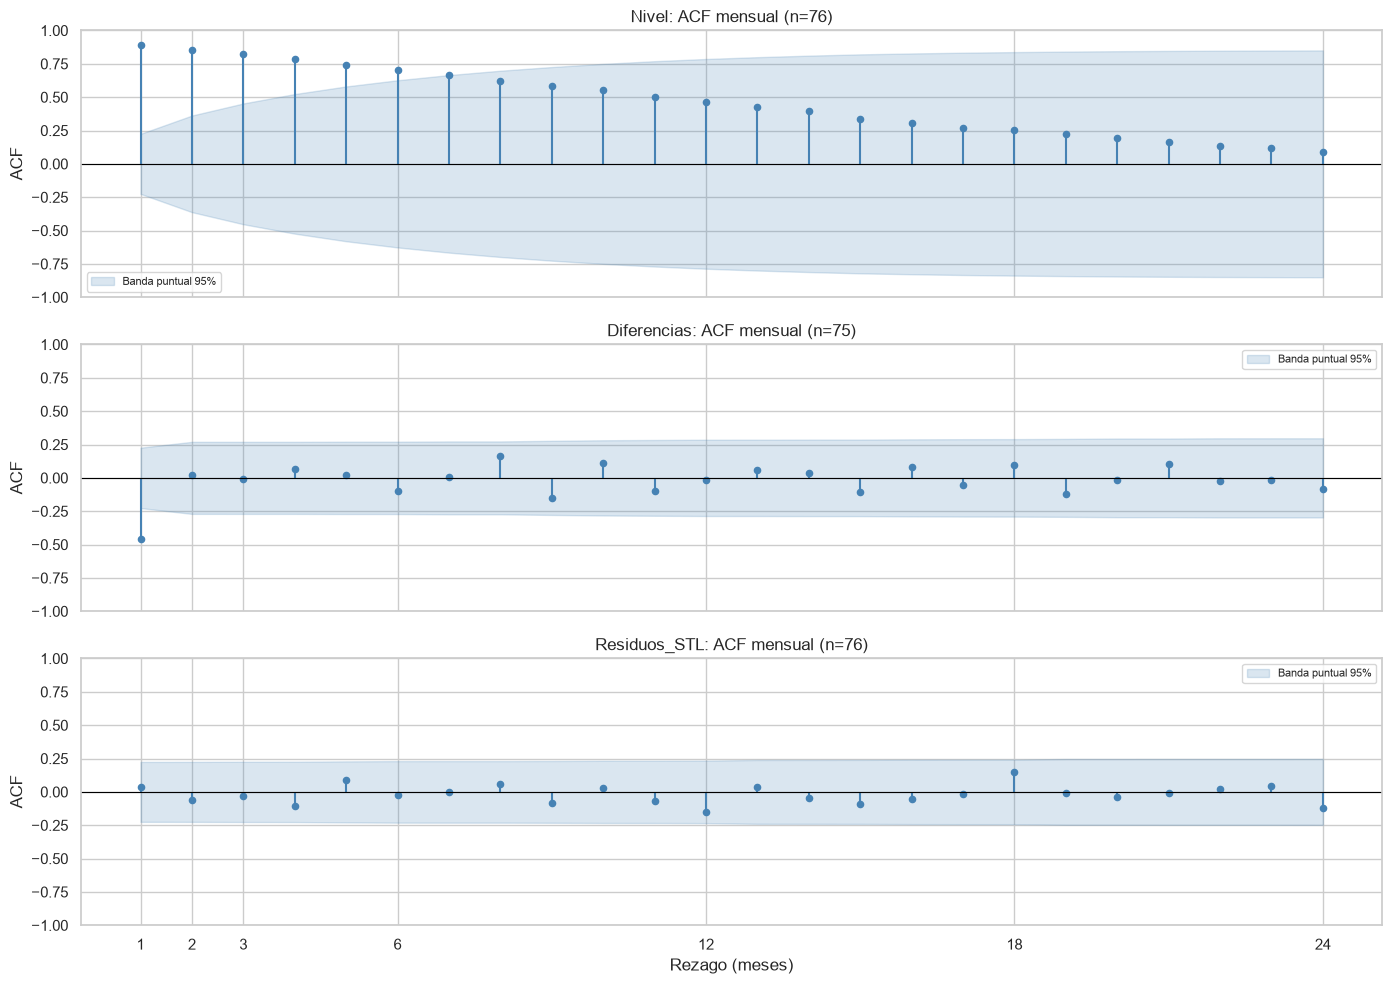

,serie,rezago,n_meses,ACF,IC95_inferior,IC95_superior,fuera_banda_95
0,Nivel,1,76,0.893,0.668,1.117,True
1,Nivel,2,76,0.855,0.493,1.217,True
2,Nivel,3,76,0.825,0.372,1.277,True
5,Nivel,6,76,0.705,0.078,1.332,True
11,Nivel,12,76,0.462,-0.325,1.248,False
23,Nivel,24,76,0.086,-0.764,0.937,False
24,Diferencias,1,75,-0.460,-0.687,-0.234,True
25,Diferencias,2,75,0.020,-0.250,0.290,False
26,Diferencias,3,75,-0.009,-0.280,0.261,False
29,Diferencias,6,75,-0.102,-0.373,0.170,False


,hasta_rezago,lb_stat,lb_pvalue,p_Holm,rechazo_Holm_5pct,serie
0,1,62.98,2.09e-15,2.09e-15,True,Nivel
1,2,121.49,4.15e-27,8.3e-27,True,Nivel
2,3,176.70,4.56e-38,1.37e-37,True,Nivel
3,6,316.30,2.63e-65,1.05e-64,True,Nivel
4,12,488.87,5.17e-97,2.59e-96,True,Nivel
5,24,571.13,2.57e-105,1.54e-104,True,Nivel
6,1,16.53,4.79e-05,0.000288,True,Diferencias
7,2,16.56,0.000253,0.00127,True,Diferencias
8,3,16.57,0.000867,0.00347,True,Diferencias
9,6,17.87,0.00656,0.0197,True,Diferencias


In [21]:
rezagos_interes = [1, 2, 3, 6, 12, 24]
series_autocorrelacion = {
    "Nivel": series_mensuales["mediana_rub"],
    "Diferencias": series_mensuales["mediana_rub"].diff().dropna(),
    "Residuos_STL": componentes_stl["residuo"],
}
resultados_acf = []
resultados_ljung_box = []
fig, axes = plt.subplots(3, 1, figsize=(14, 10), sharex=True)
for ax, (nombre, serie) in zip(axes, series_autocorrelacion.items()):
    coeficientes, intervalos = acf(serie, nlags=24, alpha=.05, fft=False,
                                  bartlett_confint=True, missing="raise")
    rezagos = np.arange(1, 25)
    banda = intervalos - coeficientes[:, None]
    ax.fill_between(rezagos, banda[1:, 0], banda[1:, 1], alpha=.2, color="steelblue", label="Banda puntual 95%")
    ax.vlines(rezagos, 0, coeficientes[1:], color="steelblue")
    ax.scatter(rezagos, coeficientes[1:], color="steelblue", s=20)
    ax.axhline(0, color="black", linewidth=.8)
    ax.set(title=f"{nombre}: ACF mensual (n={len(serie)})", ylabel="ACF", ylim=(-1, 1))
    ax.legend(fontsize=8)
    for lag in rezagos:
        resultados_acf.append({
            "serie": nombre, "rezago": lag, "n_meses": len(serie), "ACF": coeficientes[lag],
            "IC95_inferior": intervalos[lag, 0], "IC95_superior": intervalos[lag, 1],
            "fuera_banda_95": bool(intervalos[lag, 0] > 0 or intervalos[lag, 1] < 0),
        })
    pruebas = acorr_ljungbox(serie, lags=rezagos_interes, model_df=0, return_df=True)
    pruebas["p_Holm"] = multipletests(pruebas["lb_pvalue"], alpha=.05, method="holm")[1]
    pruebas["rechazo_Holm_5pct"] = pruebas["p_Holm"].lt(.05)
    pruebas["serie"] = nombre
    pruebas.index.name = "hasta_rezago"
    resultados_ljung_box.append(pruebas.reset_index())
axes[-1].set(xlabel="Rezago (meses)", xticks=[1, 2, 3, 6, 12, 18, 24])
fig.tight_layout()
plt.show()
resultados_acf = pd.DataFrame(resultados_acf)
resultados_ljung_box = pd.concat(resultados_ljung_box, ignore_index=True)
display(resultados_acf.loc[resultados_acf["rezago"].isin(rezagos_interes)].style.format({
    "ACF": "{:.3f}", "IC95_inferior": "{:.3f}", "IC95_superior": "{:.3f}"
}))
display(resultados_ljung_box.style.format({"lb_stat": "{:.2f}", "lb_pvalue": "{:.3g}", "p_Holm": "{:.3g}"}))

**Lectura:** en niveles, los rezagos 1, 2, 3, 4, 5, 6 quedan fuera de las bandas puntuales del 95 %. La ACF decae lentamente; en 12 y 24 meses vale 0.462 y 0.086, sin significación puntual con estas bandas. El rechazo conjunto de Ljung–Box en niveles es compatible con la tendencia y no demuestra un ciclo anual.

Tras diferenciar, solo el rezago 1 es significativo puntualmente (ACF -0.460). Ljung–Box conserva rechazo hasta los horizontes 1, 2, 3, 6 y 12 después de Holm, pero no en 24 (p=0.153). Son contrastes conjuntos: el rechazo hasta 12 no significa que el coeficiente del rezago 12 sea significativo. La dependencia negativa de corto plazo puede reflejar reversión de fluctuaciones y también el efecto de diferenciar niveles con ruido.

En los residuos STL no hay coeficientes significativos puntualmente hasta 24 meses y Ljung–Box no rechaza en los horizontes revisados (p originales entre 0.769 y 0.985). No se detecta dependencia adicional clara bajo esta descomposición; no demuestra independencia: solo hay 76 meses, STL se estimó sobre los mismos datos y el horizonte 24 utiliza 52 pares de meses. Estos residuos son de STL, no de un modelo OLS.

### 6.4. Conclusiones e implicaciones para la evaluación de OLS

- **¿Existe tendencia en `price_rub`?** Sí: la mediana aumenta 68.22 % nominal entre enero de 2020 y abril de 2026, con crecimiento inicial y oscilaciones posteriores. La media móvil y STL sostienen la lectura de un cambio de nivel; los agregados pueden reflejar composición de la oferta.
- **¿Hay estacionalidad por mes?** No se observa un patrón anual claro y estable tras ajustar nivel y tendencia. Hay indicios pequeños en algunos meses, pero solo seis ciclos completos, signos interanuales variables y 2026 parcial: evidencia insuficiente para afirmar un efecto fijo de abril, junio u otro mes.
- **¿También ocurre en `price_per_sqm`?** Sí para el crecimiento general: su mediana aumenta 65.97 %. La comparación ajustada no confirma una estacionalidad mensual común robusta en ambos indicadores.
- **¿Qué rezagos muestran autocorrelación?** En niveles, 1–6 meses según bandas puntuales del 95 %; Ljung–Box rechaza conjuntamente en los horizontes analizados. Los rezagos anuales 12 y 24 no destacan como efectos específicos significativos con esas bandas.
- **¿Persiste al quitar tendencia?** En primeras diferencias persiste una ACF negativa significativa en el rezago 1; en residuos STL no se detecta autocorrelación significativa hasta 24 meses. La conclusión depende del tratamiento de tendencia y no prueba independencia de anuncios individuales ni de futuros errores OLS.

**Implicación metodológica:** el cambio de nivel temporal y la dependencia de los agregados justifican investigar una partición cronológica y validación con ventanas temporales **si el objetivo es predecir anuncios futuros**. Una división aleatoria podría mezclar regímenes y contexto mensual compartido y ofrecer una evaluación optimista. La autocorrelación por sí sola no obliga a esa partición: debe definirse primero el escenario de predicción. Para una muestra contemporánea también habrá que considerar los grupos y períodos compartidos, y comprobar después los residuos del OLS que se entrene.

STL usa información de toda la serie, incluida información posterior a cada mes: sus componentes son exclusivamente exploratorios y no se incorporan como predictores. Imputaciones y cualquier transformación futura deberán ajustarse dentro de entrenamiento en cada partición. En esta sección **no se entrenaron modelos, no se dividieron los datos ni se seleccionaron características**.

Referencias de implementación: [STL](https://www.statsmodels.org/stable/generated/statsmodels.tsa.seasonal.STL.html), [bandas de la ACF](https://www.statsmodels.org/stable/generated/statsmodels.graphics.tsaplots.plot_acf.html) y [Ljung–Box](https://www.statsmodels.org/stable/generated/statsmodels.stats.diagnostic.acorr_ljungbox.html), documentación de statsmodels.
